In [ ]:
#Importation des librairies
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from statsmodels.tsa.seasonal import seasonal_decompose
import numpy as np
from scipy.stats import norm
from scipy.stats import shapiro
from scipy.stats import f_oneway
from scipy.stats import kruskal
from scipy.stats import pearsonr
from scipy.stats import spearmanr

In [ ]:
#Affichage de toutes les colonnes d'un dataframe
pd.options.display.max_columns = None
pd.options.display.max_rows = None
pd.options.display.float_format = "{:.2f}".format

# P10 - Analyse des saisonnalités des ventes d'une activité e-commerce pour gérer au mieux les variations d'activité

## 1/ Exploration du jeu de données



### 1.1 Chargement des données

In [ ]:
#Importation des fichiers
#DataSet complet : périmètre 2017-2022
df_p9 = pd.read_excel("dataset_p9.xlsx")

In [ ]:
#Création DF : périmètre mission 2019-2022
df = df_p9[(df_p9["date"].dt.year >= 2019) &(df_p9["date"].dt.year <= 2022)].copy()

### 1.2 Ordres de grandeur et indicateurs statistiques basiques

#### 1.2.1 Premières et dernières lignes du jeu de données

In [ ]:
#5 premières lignes de la table
df.head()

,date,product,sales
730,2019-01-01,tomate,128.89
731,2019-01-02,tomate,121.19
732,2019-01-03,tomate,129.49
733,2019-01-04,tomate,111.83
734,2019-01-05,tomate,121.21


In [ ]:
#5 dernières lignes de la table
df.tail()

,date,product,sales
32860,2022-12-27,mangue,44.86
32861,2022-12-28,mangue,39.63
32862,2022-12-29,mangue,42.04
32863,2022-12-30,mangue,43.91
32864,2022-12-31,mangue,44.58


Une ligne du dataset correspond au CA de vente en EUR d'un produit  à une date donnée

#### 1.2.2 Structure du jeu de données

In [ ]:
#Dimensions du dataset complet
print("Le dataset complet comporte {} ligne(s)".format(df_p9.shape[0]))
print("Le dataset complet comporte {} colonne(s)".format(df_p9.shape[1]))
print("période du dataset complet : {} à {}".format(df_p9['date'].min(), df_p9['date'].max()))
#Dimensions du dataset mission : 4 dernières années
print("Le dataset de la mission comporte {} ligne(s)".format(df.shape[0]))
print("Le dataset de la mission comporte {} colonne(s)".format(df.shape[1]))
print("période du dataset complet : {} à {}".format(df['date'].min(), df['date'].max()))

Le dataset complet comporte 32865 ligne(s)
Le dataset complet comporte 3 colonne(s)
période du dataset complet : 2017-01-01 00:00:00 à 2022-12-31 00:00:00
Le dataset de la mission comporte 21915 ligne(s)
Le dataset de la mission comporte 3 colonne(s)
période du dataset complet : 2019-01-01 00:00:00 à 2022-12-31 00:00:00


In [ ]:
#Nature des données
df.dtypes

,0
date,datetime64[ns]
product,object
sales,float64


*   Date = contient date au format YYYY-MM-DD
*   product = contient nom du produit
*   sales = contient le CA des ventes en EUR

#### 1.2.3 Valeurs manquantes et doublons

In [ ]:
#Valeurs manquantes et doublons
print("Valeurs manquantes :")
print(df.isna().sum())
print("Doublons :", df.duplicated().sum())

Valeurs manquantes :
date       0
product    0
sales      0
dtype: int64
Doublons : 0


#### 1.2.4 Indicateurs statistiques

In [ ]:
print(df["sales"].describe())

count   21915.00
mean       97.82
std        38.30
min         0.98
25%        70.28
50%        92.10
75%       122.79
max       228.91
Name: sales, dtype: float64


Text(0, 0.5, "Nombre d'observations")

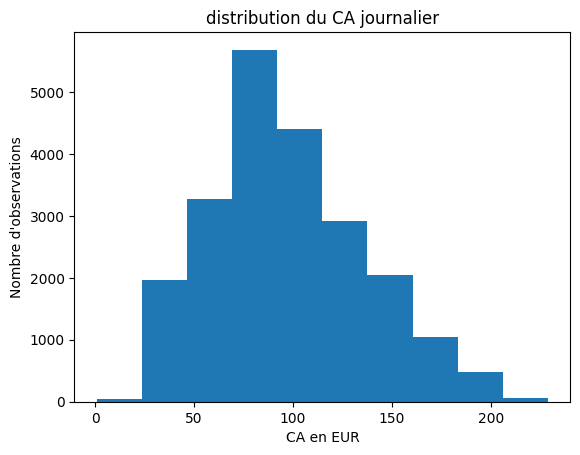

In [ ]:
plt.hist(df['sales'])
plt.title('distribution du CA journalier')
plt.xlabel('CA en EUR')
plt.ylabel("Nombre d'observations")

*   21915 ventes
*   Moyenne CA = 97.82 eur et médiane 92.1. La distribution est légèrement asymétrique
*   Écart type de 38.3 : l'écart type est élevé par rapport à la moyenne ce qui signifie que la dispersion des ventes est forte, avec une variation importante d'une vente à l'autre




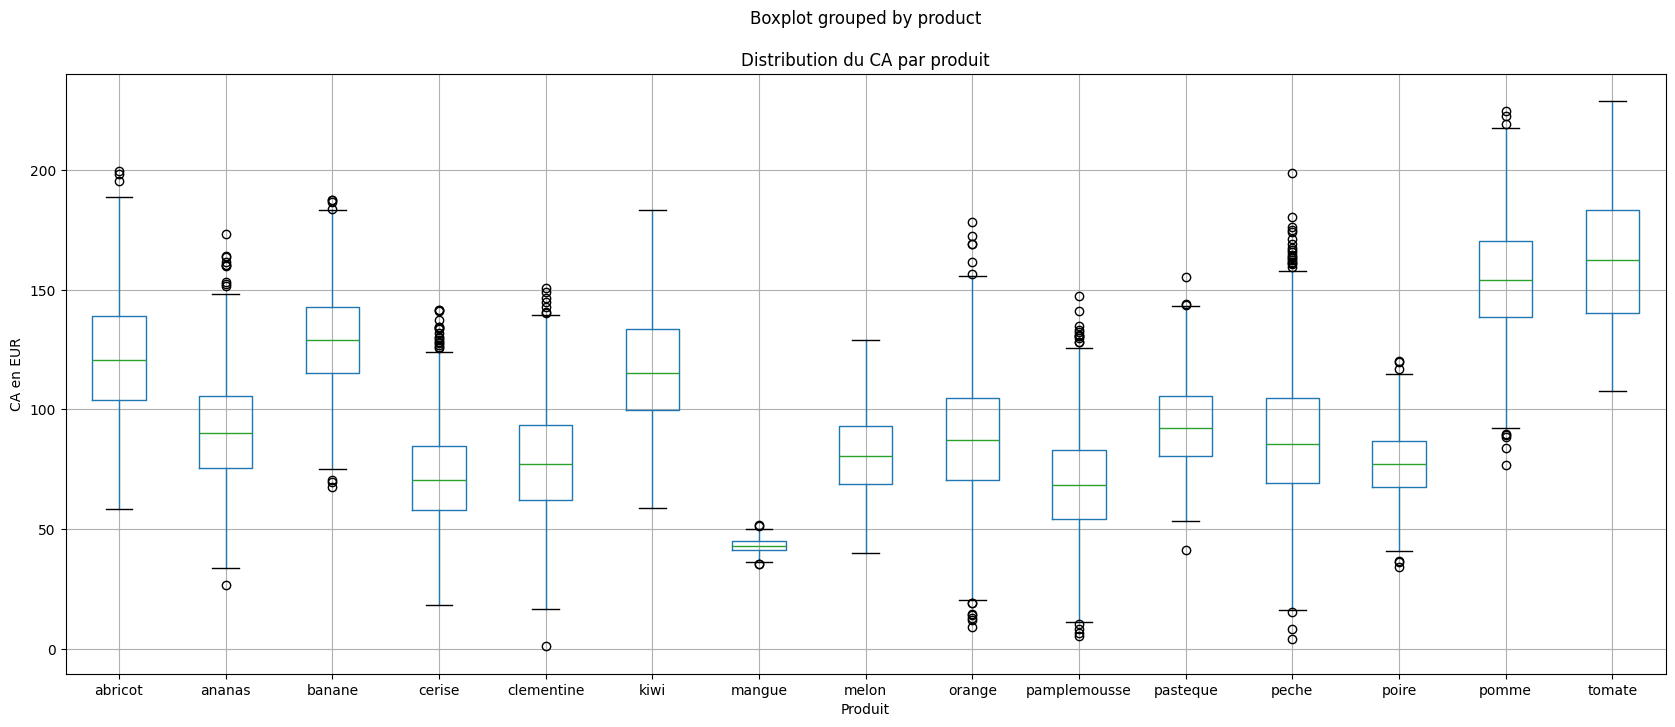

In [ ]:
#Description de la distribution statistique du CA par produit sur l’ensemble des produits.
#Création d'une boîte à moustache
fig, ax = plt.subplots(figsize=(20, 8))
df.boxplot(column="sales", by="product", ax=ax)
ax.set_title("Distribution du CA par produit")
ax.set_xlabel("Produit")
ax.set_ylabel("CA en EUR")
plt.show()

In [ ]:
#Autre méthode avec plotly express
px.box(df,x="product",y="sales",title="Distribution du CA par produit")


*    La distribution du CA change beaucoup selon le fruit : médiane basse pour la mangue, médiane haute pour la tomate et la pomme
*   Certains fruits ont une distribution resserrée (mangue, poire) : les ventes varient peu. D'autres ont une distribution étalée (tomate, abricot, orange) : les ventes varient beaucoup
*   outliers hauts pour cerise, pêche, clémentine, orange, ananas : quelques ventes nettement au-dessus du reste
*   outliers bas pour ananas, clémentine, pamplemousse, poire : quelques ventes tres en dessous du reste

#### 1.2.5 Analyse de la variable 'Product'

In [ ]:
#Valeurs distinctes de la colonne product
print("Les valeurs distinctes de la colonnes product sont : {}".format(df ["product"].unique()))
print("Le nombre de produits distincts est de {}".format(df["product"].nunique()))

Les valeurs distinctes de la colonnes product sont : ['tomate' 'pomme' 'banane' 'abricot' 'kiwi' 'pasteque' 'ananas' 'peche'
 'orange' 'melon' 'poire' 'clementine' 'cerise' 'pamplemousse' 'mangue']
Le nombre de produits distincts est de 15


#### 1.2.6 Analyse de la variable 'Date' : contrôle des données temporelles

- Est-ce que toutes les dates sont converties correctement ?

In [ ]:
df.dtypes

,0
date,datetime64[ns]
product,object
sales,float64


In [ ]:
df['date'].isna().sum()

np.int64(0)

In [ ]:
df['date'].min(), df['date'].max()

(Timestamp('2019-01-01 00:00:00'), Timestamp('2022-12-31 00:00:00'))

La variable 'date' est au format datetime, aucune date n'est manquante et la période du data set couvre les données du 01/01/2019 au 31/12/2022 qui correspond bien au data set mission.

- Ai-je une seule valeur par date, ou une règle explicite si plusieurs ?

In [ ]:
df.duplicated(['date', 'product']).sum()

np.int64(0)

Une ligne correspond à une date donnée pour un article. Il n'y a aucun doublon sur le couple date/produit.

La série est-elle continue sur la fréquence choisie ?

In [ ]:
df.groupby('product')['date'].nunique()

,date
product,
abricot,1461
ananas,1461
banane,1461
cerise,1461
clementine,1461
kiwi,1461
mangue,1461
melon,1461
orange,1461


Chaque produit a bien 1461 jours de données, soit tous les jours du 01/01/2019 au 31/12/2022(365*3+366 = 1461). La série est donc continue pour chaque produit.

#### 1.2.7 Analyse du CA par produit et par année

In [ ]:
#Total CA par produit
ca_global = df["sales"].sum()
print("Le CA global sur les quatre années est de {} EUR".format(ca_global))

df_total_sales = df.groupby('product')['sales'].sum().sort_values(ascending=False)
df_total_sales = df_total_sales.reset_index()

Le CA global sur les quatre années est de 2143722.796130667 EUR


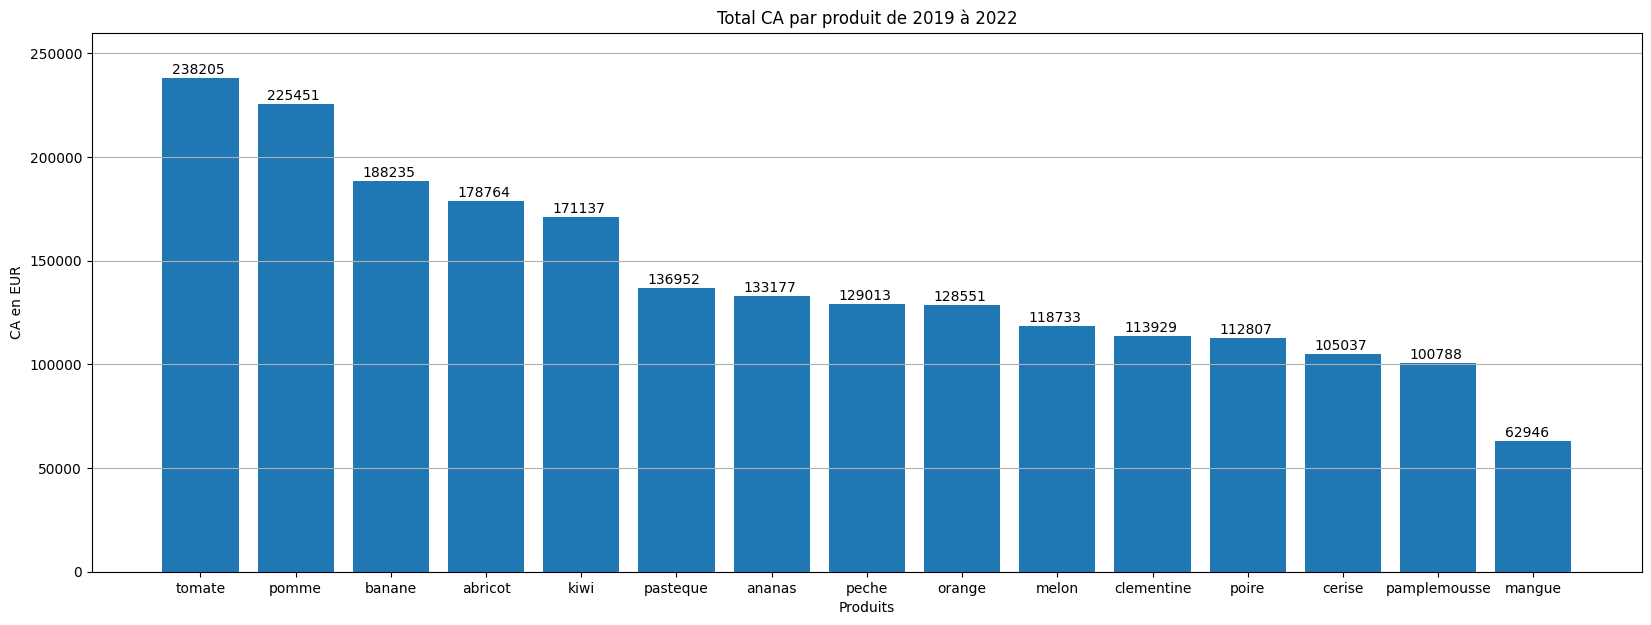

In [ ]:
#Répartition du CA global de 2019 à 2022 par produit
plt.figure(figsize=(20, 7))
plt.bar(height=df_total_sales['sales'], x=df_total_sales['product'])
plt.ylim(0,260000)
plt.title('Total CA par produit de 2019 à 2022')
plt.xlabel('Produits')
plt.ylabel('CA en EUR')
plt.grid(axis ='y')

ca = df_total_sales['sales'].tolist()
for i in range (15):
  plt.text(i-0.3,ca[i]+2000, round(ca[i]))
plt.show()

In [ ]:
#La part du CA pour les différents produits au global sur les 4 ans

# 20 / 80 en CA
#Création colonne de la part du CA de la ligne dans le dataset
df_total_sales["Part_CA_%"] = df_total_sales["sales"] / ca_global *100
#Création colonne réalisant la somme cumulative de la colonne précedemment créée
df_total_sales["Part_CA_%_cumulé"] = df_total_sales["Part_CA_%"].cumsum()
#Nombre d'articles représentant 80% du CA
print ("le nombre de produits représentant 80% du CA est {}".format(df_total_sales.loc[df_total_sales["Part_CA_%_cumulé"]<80].shape[0]+1))
print ("Cela représente {:.0f} % des produits".format((df_total_sales.loc[df_total_sales["Part_CA_%_cumulé"]<80].shape[0]+1)/df_total_sales.shape[0]*100))
df_total_sales.head(15)


le nombre de produits représentant 80% du CA est 11
Cela représente 73 % des produits


,product,sales,Part_CA_%,Part_CA_%_cumulé
0,tomate,238205.13,11.11,11.11
1,pomme,225451.24,10.52,21.63
2,banane,188235.31,8.78,30.41
3,abricot,178763.88,8.34,38.75
4,kiwi,171136.63,7.98,46.73
5,pasteque,136952.41,6.39,53.12
6,ananas,133177.25,6.21,59.33
7,peche,129012.52,6.02,65.35
8,orange,128550.52,6.00,71.35
9,melon,118733.06,5.54,76.89


In [ ]:
#Ajout variable année et mois
df["annee"] = df["date"].dt.year
df["mois"] = df["date"].dt.month

#CA de vente global par année
ca_annee = df.groupby("annee")["sales"].sum()
print("Le CA par année est de {}".format(ca_annee))

Le CA par année est de annee
2019   529662.76
2020   532656.95
2021   539035.51
2022   542367.58
Name: sales, dtype: float64


In [ ]:
#Evolution du CA global
evolution_ca = (ca_annee[2022]-ca_annee[2019])/ca_annee[2019]*100
print (evolution_ca)

2.398660846888191


In [ ]:
#Evolution du CA par produit
df_ca_annee = df.pivot_table ( index = "product", columns='annee', values= 'sales',aggfunc='sum')
df_ca_annee['taux_Evolution_19_vs_22'] = (df_ca_annee[2022]-df_ca_annee[2019]) / df_ca_annee[2019] *100
df_ca_annee.sort_values('taux_Evolution_19_vs_22', ascending=False)

annee,2019,2020,2021,2022,taux_Evolution_19_vs_22
product,,,,,
tomate,56575.57,58553.41,60410.92,62665.22,10.76
clementine,27981.27,27945.39,28244.97,29756.88,6.35
pomme,54465.61,55673.80,57576.89,57734.93,6.00
poire,27608.41,27886.37,28270.65,29041.18,5.19
orange,31743.60,31728.83,32659.08,32419.01,2.13
pamplemousse,24593.32,24388.36,26792.12,25013.74,1.71
kiwi,42444.06,42874.74,42863.19,42954.63,1.20
melon,29770.87,29385.43,29670.79,29905.97,0.45
banane,46891.23,47481.64,46911.88,46950.55,0.13


*   CA global plutôt stable : +2.4 % entre 2019 et 2022
*   Hausse surtout portée par : tomate (+10.8 %), clémentine (+6.4 %), pomme (+6 %) et poire (+5.2 %)
*   Quelques baisses mais assez faibles : pêche (-2.4 %), abricot (-1.1 %), cerise (-0.6 %)
*   CA global stable malgré des évolutions différentes selon les produits

In [ ]:
#La part du CA pour les différents produits au global  par an
df_ca_annee['Part_2019_%'] = df_ca_annee[2019] / df_ca_annee[2019].sum() * 100
df_ca_annee['Part_2020_%'] = df_ca_annee[2020] / df_ca_annee[2020].sum() * 100
df_ca_annee['Part_2021_%'] = df_ca_annee[2021] / df_ca_annee[2021].sum() * 100
df_ca_annee['Part_2022_%'] = df_ca_annee[2022] / df_ca_annee[2022].sum() * 100

In [ ]:
df_ca_annee_part = df_ca_annee.loc[:, ['Part_2019_%','Part_2020_%','Part_2021_%', 'Part_2022_%']]
df_ca_annee_part

annee,Part_2019_%,Part_2020_%,Part_2021_%,Part_2022_%
product,,,,
abricot,8.48,8.43,8.27,8.18
ananas,6.34,6.17,6.14,6.20
banane,8.85,8.91,8.70,8.66
cerise,4.97,4.99,4.81,4.83
clementine,5.28,5.25,5.24,5.49
kiwi,8.01,8.05,7.95,7.92
mangue,2.97,2.96,2.93,2.90
melon,5.62,5.52,5.50,5.51
orange,5.99,5.96,6.06,5.98


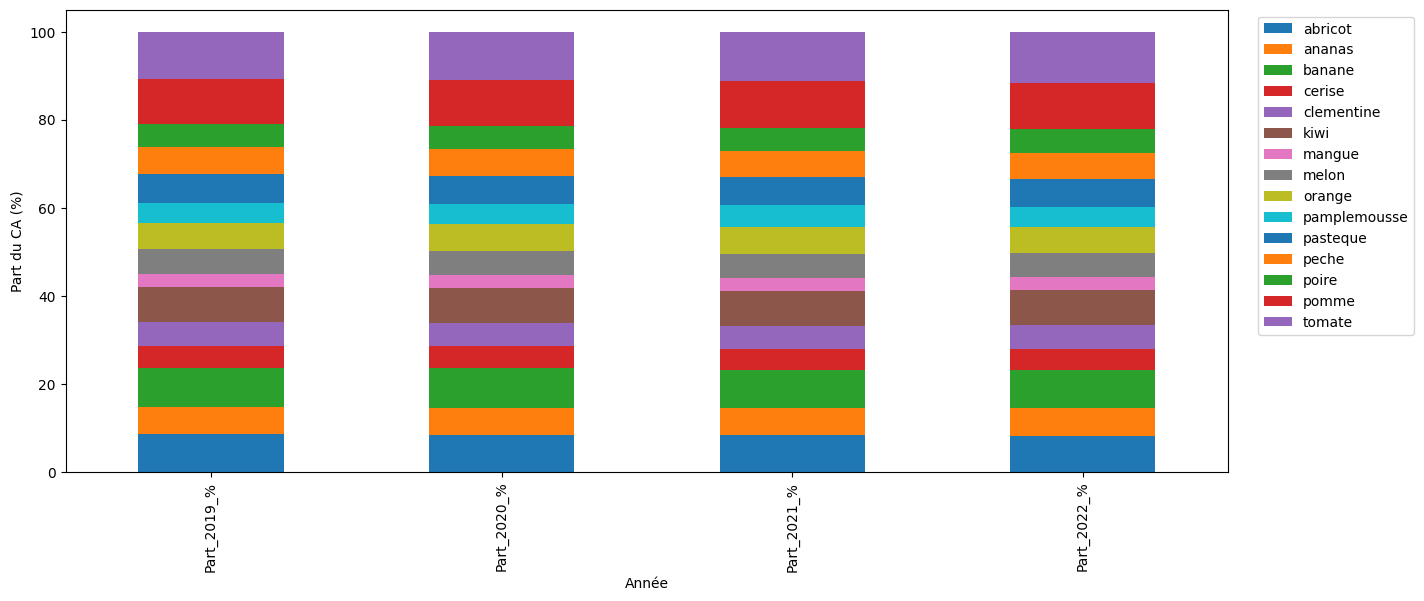

In [ ]:
df_ca_annee_part.T.plot(kind="bar",stacked=True,figsize=(15, 6))

plt.ylabel("Part du CA (%)")
plt.xlabel("Année")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

La répartition du CA par produit et par année reste stable entre 2019 et 2022. Il n’y a pas de changement important.

# 2/ Analyse des saisonnalités du top 5 des produits

### 2.1 Visualisation des données : évolution globale du CA, jour/an/mois

In [ ]:
#EVOLUTION DU CA DE 2019 à 2022 par date
evolution_ca = df.groupby("date")["sales"].sum()
evolution_ca = evolution_ca.reset_index()
evolution_ca.head()

,date,sales
0,2019-01-01,1529.97
1,2019-01-02,1447.64
2,2019-01-03,1394.90
3,2019-01-04,1383.70
4,2019-01-05,1360.86


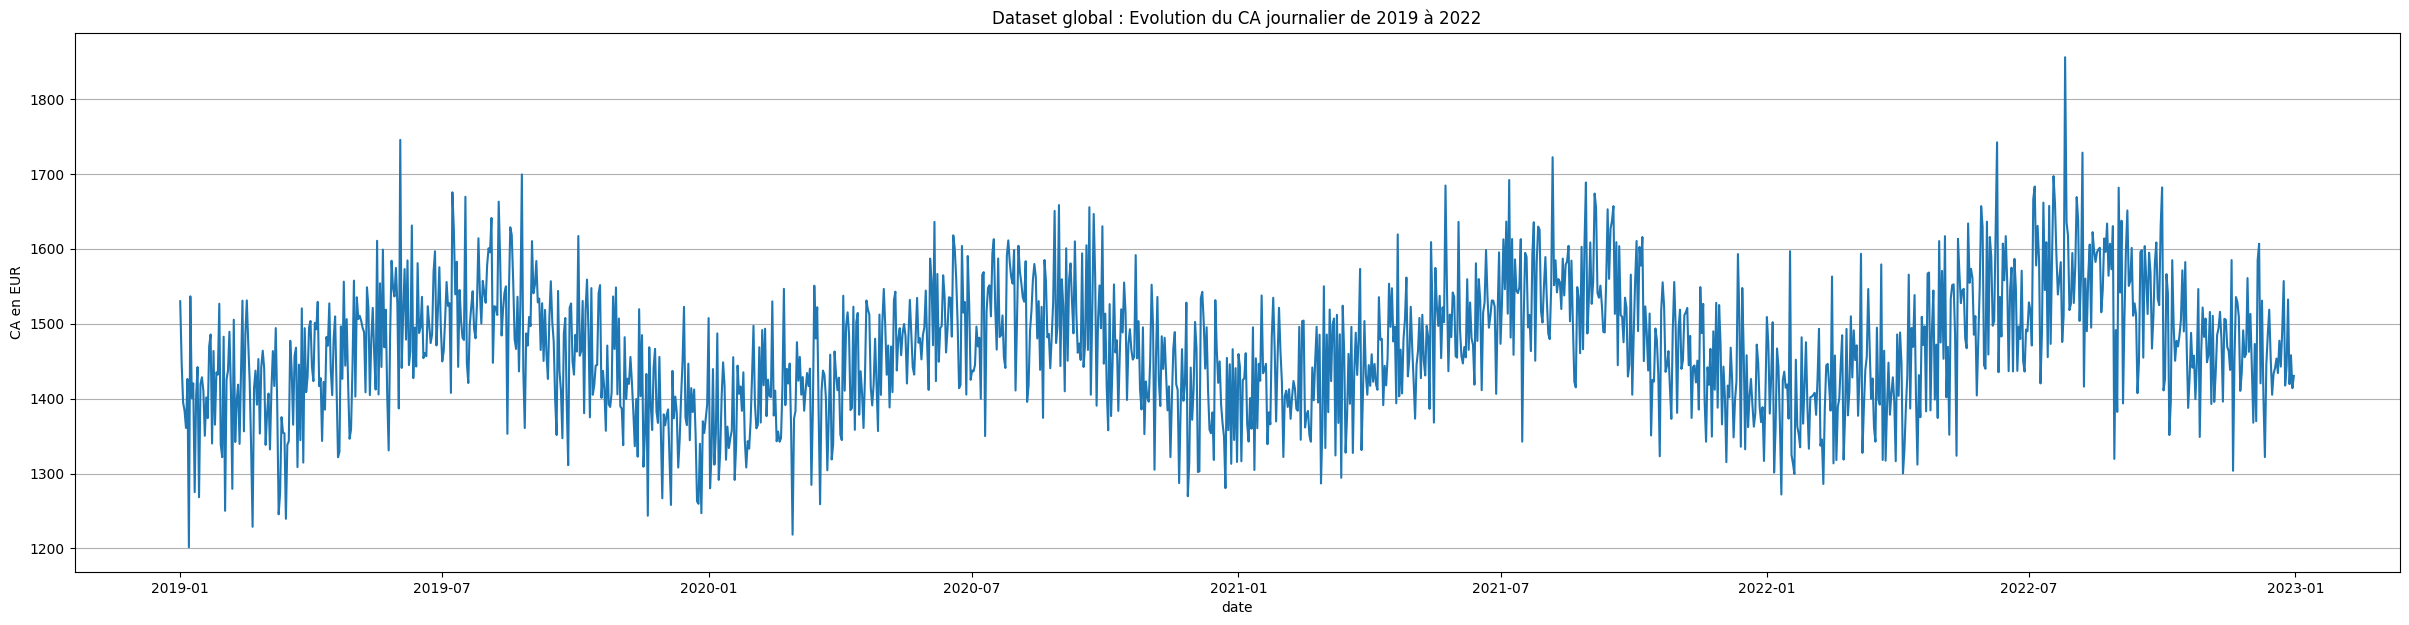

In [ ]:
#COURBE EVOLUTION DU CA DE 2019 à 2022 par date
plt.figure(figsize=(30, 7))
plt.plot(evolution_ca['date'], evolution_ca["sales"])
plt.title('Dataset global : Evolution du CA journalier de 2019 à 2022')
plt.xlabel('date')
plt.ylabel('CA en EUR')
plt.grid(axis ='y')

In [ ]:
#COURBE avec plotly express : EVOLUTION DU CA DE 2019 à 2022 par date
fig = px.line(evolution_ca,
    x= "date",
    y= "sales",
    labels={"x": "Date", "y": "CA en EUR"},
    title="Dataset global : Evolution du CA journalier de 2019 à 2022",)
fig.show()

* L'évolution du CA global montre une forte saisonnalité, avec une hausse autour de juillet et une baisse autour de janvier, qui se répète chaque année


In [ ]:
evolution_ca.set_index('date',inplace=True)
evolution_ca.head()

,sales
date,
2019-01-01,1529.97
2019-01-02,1447.64
2019-01-03,1394.90
2019-01-04,1383.70
2019-01-05,1360.86


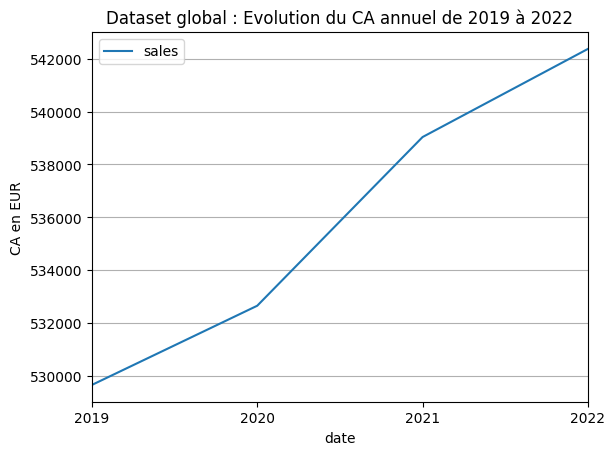

In [ ]:
#year wise
evolution_ca.resample ('YE').sum().plot()
plt.title('Dataset global : Evolution du CA annuel de 2019 à 2022')
plt.xlabel('date')
plt.ylabel('CA en EUR')
plt.grid(axis ='y')

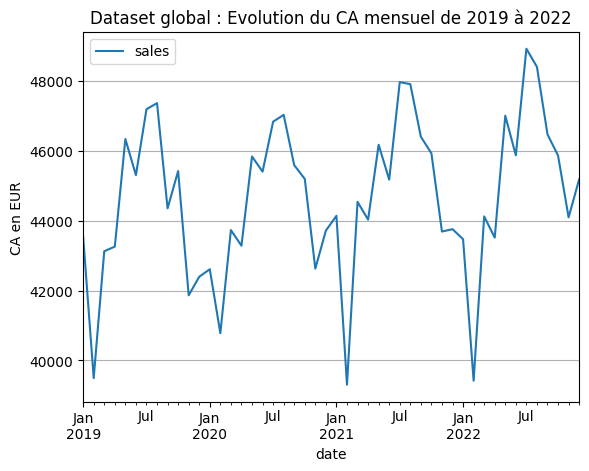

In [ ]:
#month wise
evolution_ca.resample ('ME').sum().plot()
plt.title('Dataset global : Evolution du CA mensuel de 2019 à 2022')
plt.xlabel('date')
plt.ylabel('CA en EUR')
plt.grid(axis ='y')


### 2.2 Sélection du top 5

In [ ]:
#TOP 5  CA par produit
df_top_5 = df.groupby('product')['sales'].sum().sort_values(ascending=False).head(5)
df_top_5 = df_top_5.reset_index()

df_top_5

,product,sales
0,tomate,238205.13
1,pomme,225451.24
2,banane,188235.31
3,abricot,178763.88
4,kiwi,171136.63


In [ ]:
df_top_5 = df.loc[(df['product']==('tomate'))|(df['product']==('pomme'))|(df['product']==('banane'))|(df['product']==('abricot'))|(df['product']==('kiwi')) , :]
df_top_5.head()


,date,product,sales,annee,mois
730,2019-01-01,tomate,128.89,2019,1
731,2019-01-02,tomate,121.19,2019,1
732,2019-01-03,tomate,129.49,2019,1
733,2019-01-04,tomate,111.83,2019,1
734,2019-01-05,tomate,121.21,2019,1


In [ ]:
ca_top5 = df_top_5["sales"].sum()
print("Le CA du TOP 5 sur les quatre années est de {:.0f} EUR".format(ca_top5))
print("Le CA du TOP 5 représente {:.2f}% du CA global".format((ca_top5)/(ca_global)*100))
ca_annee_top5 = df_top_5.groupby("annee")["sales"].sum()
print(ca_annee_top5)
#Evolution du CA du TOP5
evolution_ca_top5 = (ca_annee_top5[2022]-ca_annee_top5[2019])/ca_annee_top5[2019]*100
print("l'évolution du CA entre 2019 et 2022 du top 5 est de {:.2f}%".format(evolution_ca_top5))


Le CA du TOP 5 sur les quatre années est de 1001792 EUR
Le CA du TOP 5 représente 46.73% du CA global
annee
2019   245276.42
2020   249461.73
2021   252362.21
2022   254691.81
Name: sales, dtype: float64
l'évolution du CA entre 2019 et 2022 du top 5 est de 3.84%


### 2.3 Analyse de l'évolution du CA par produit (jour, année, mois)

####Analyse / jour

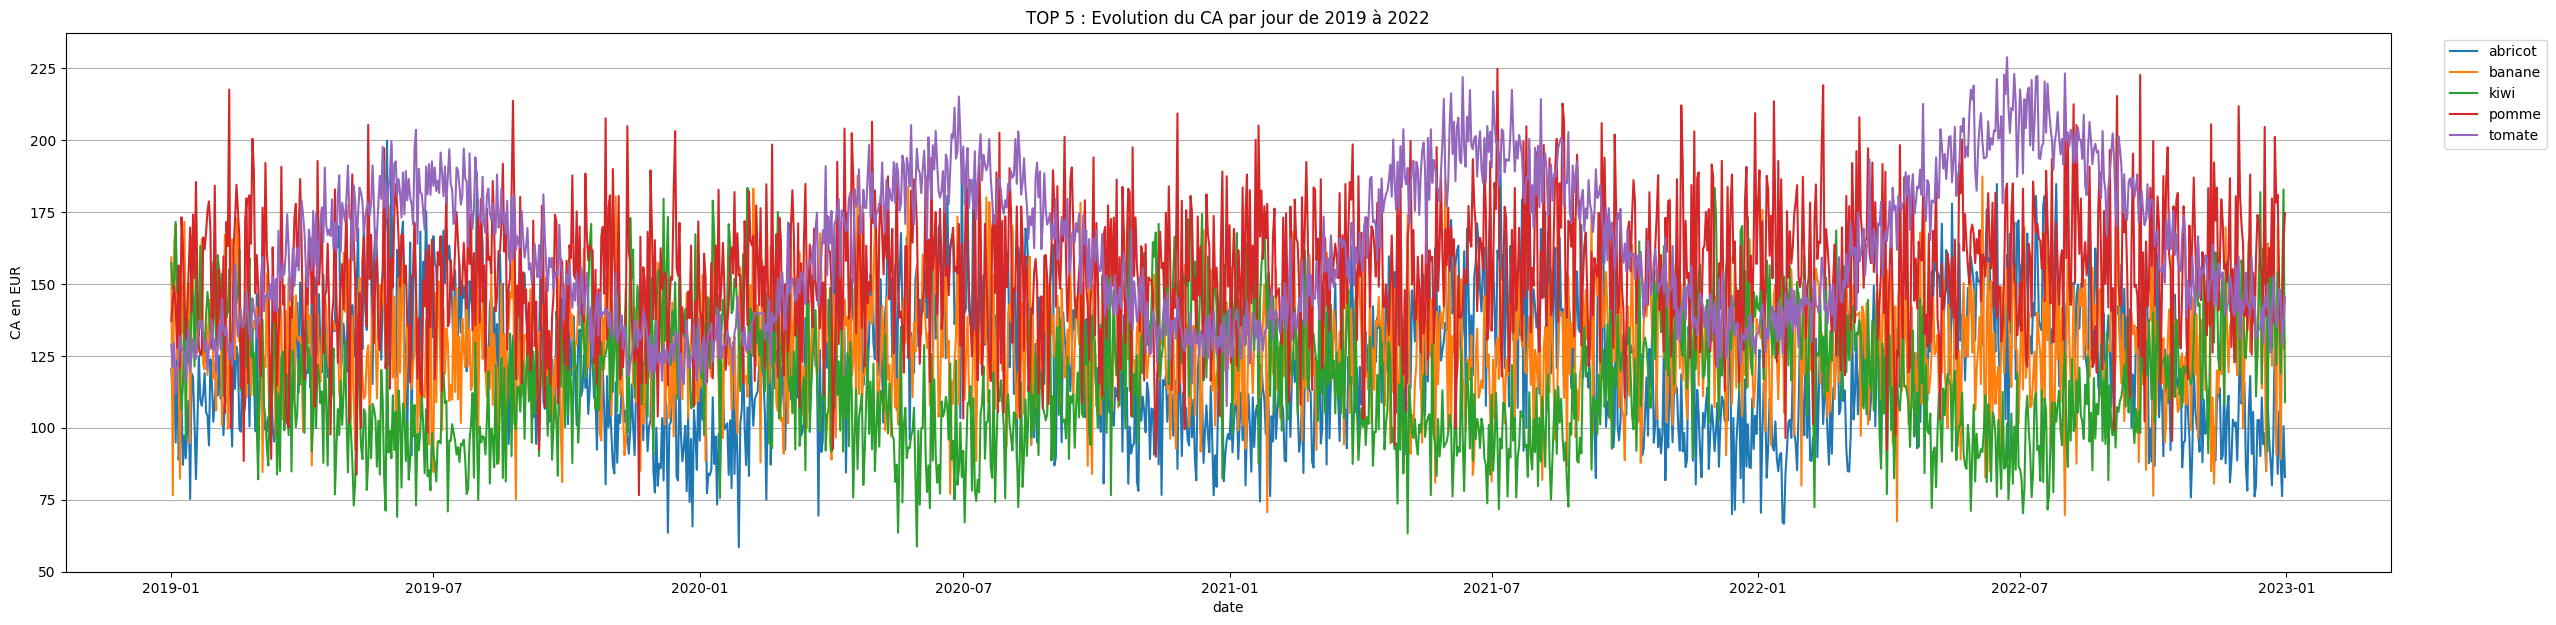

In [ ]:
df_top_5 = df_top_5.reset_index()

groups = df_top_5.groupby("product")

plt.figure(figsize=(30, 7))

for product, df in groups:
    plt.plot(df["date"], df["sales"], label=product)

plt.title("TOP 5 : Evolution du CA par jour de 2019 à 2022")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xlabel("date")
plt.ylabel("CA en EUR")
plt.grid(axis="y")

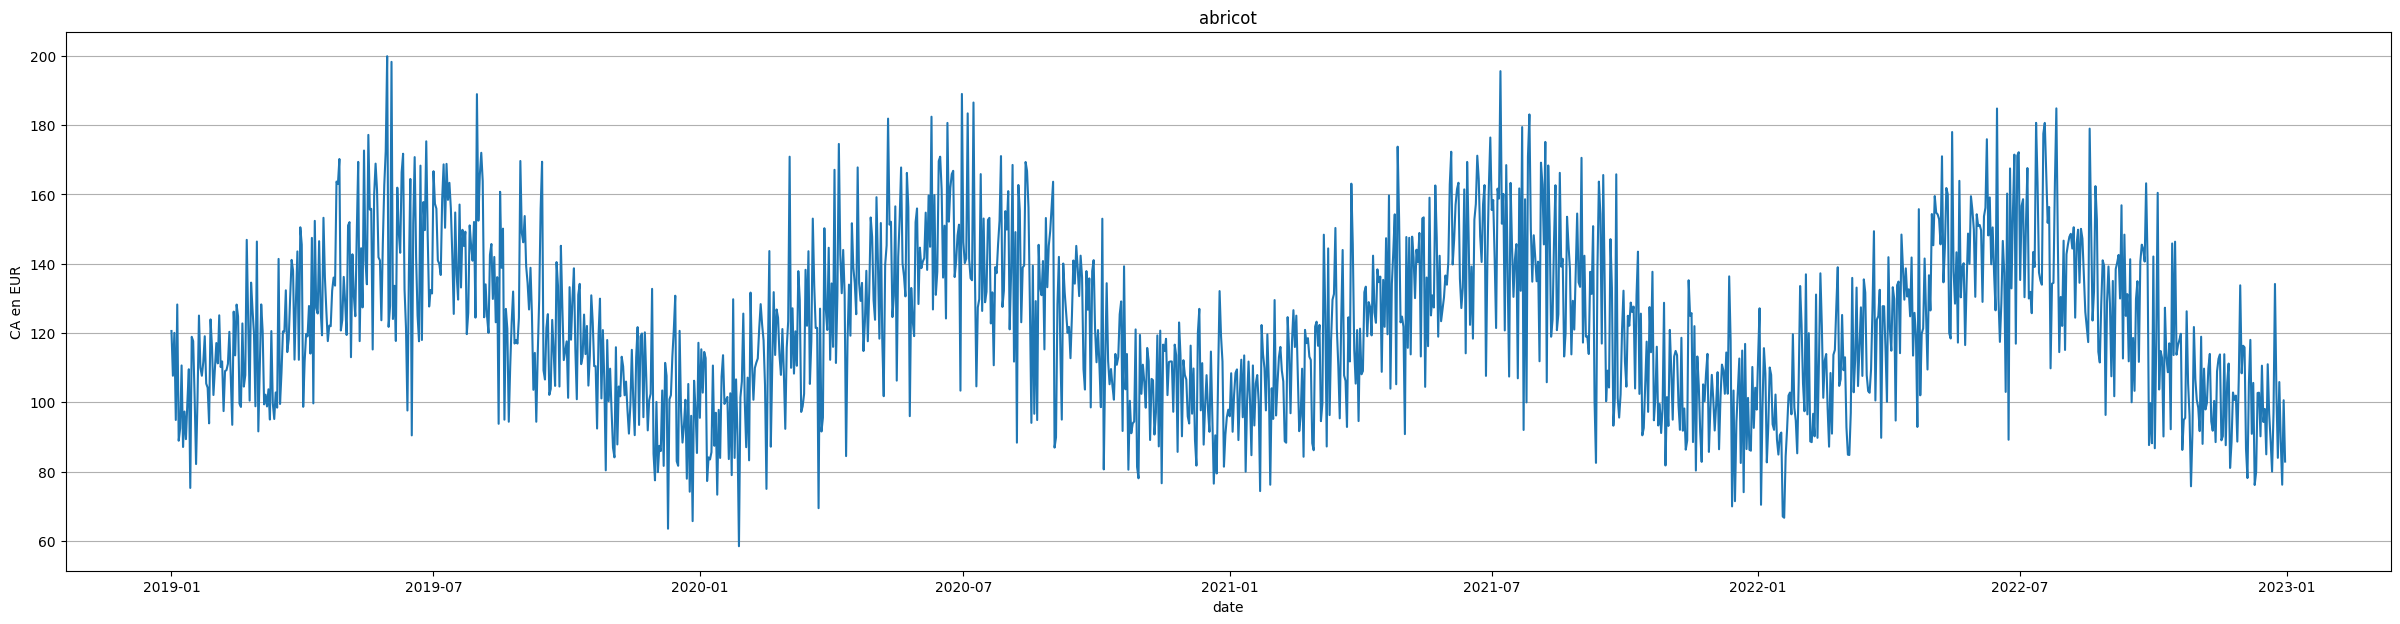

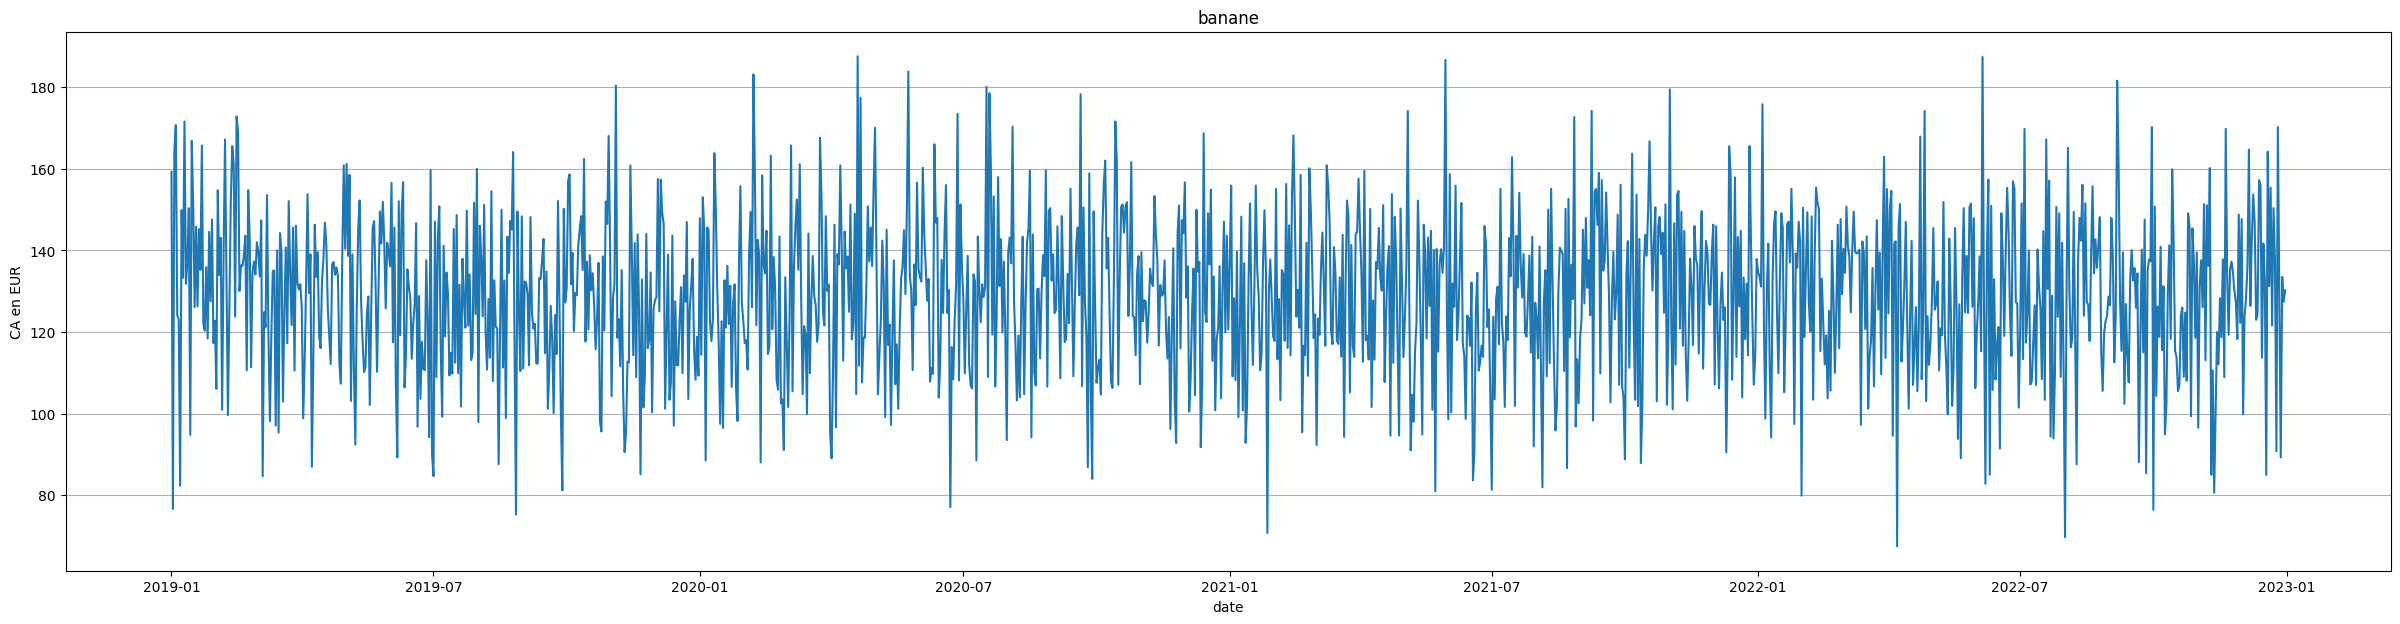

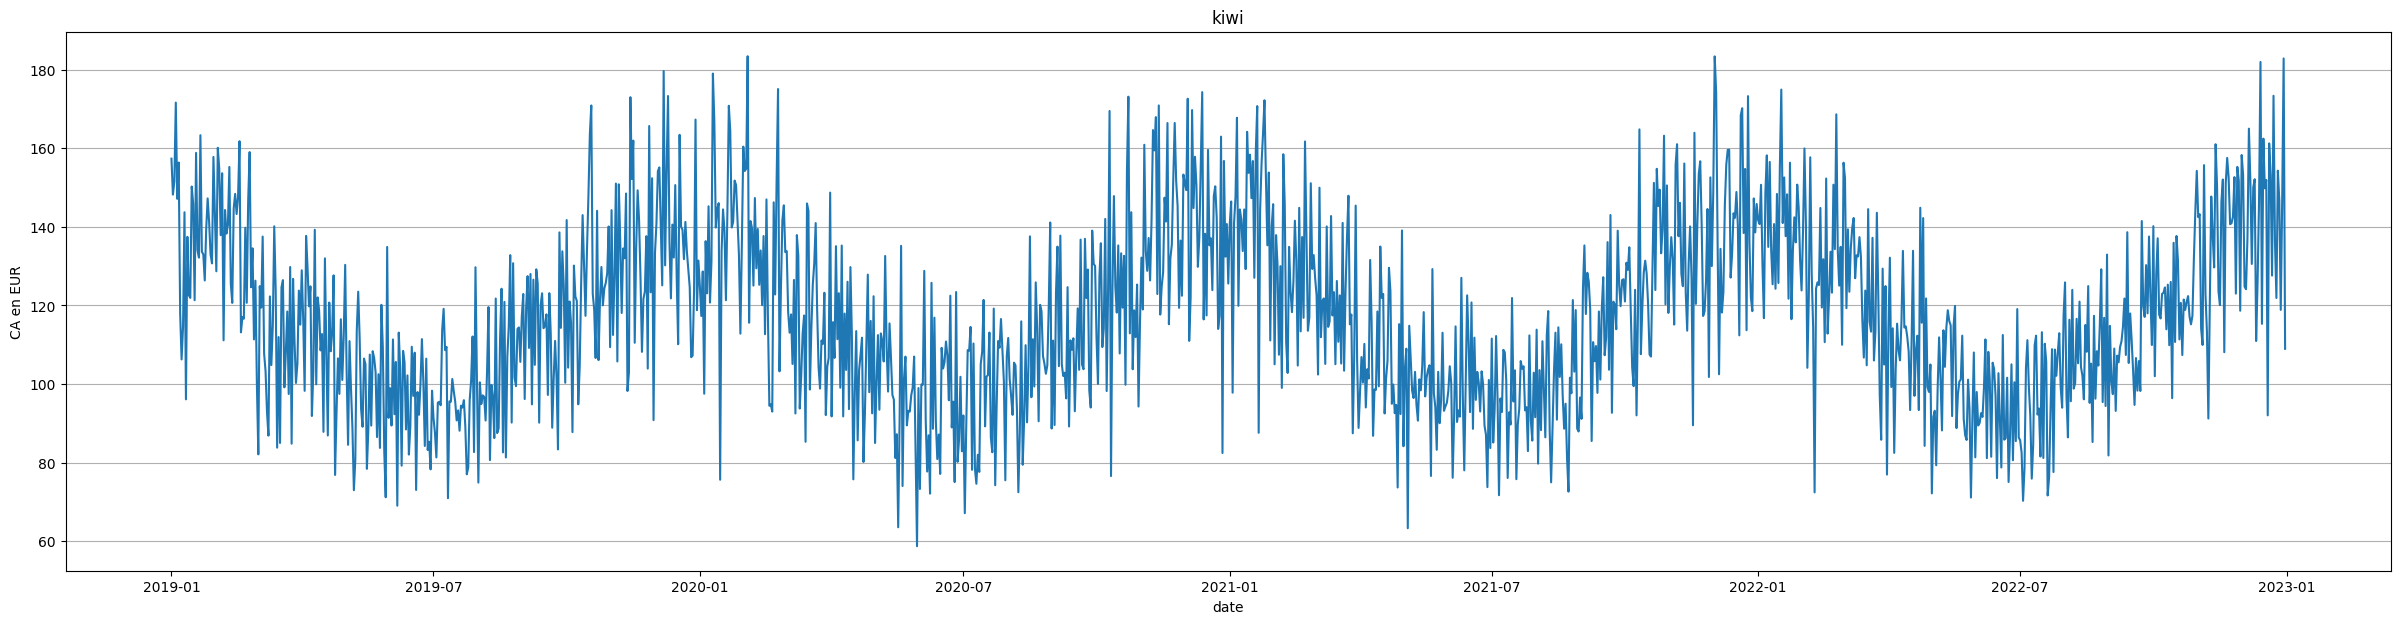

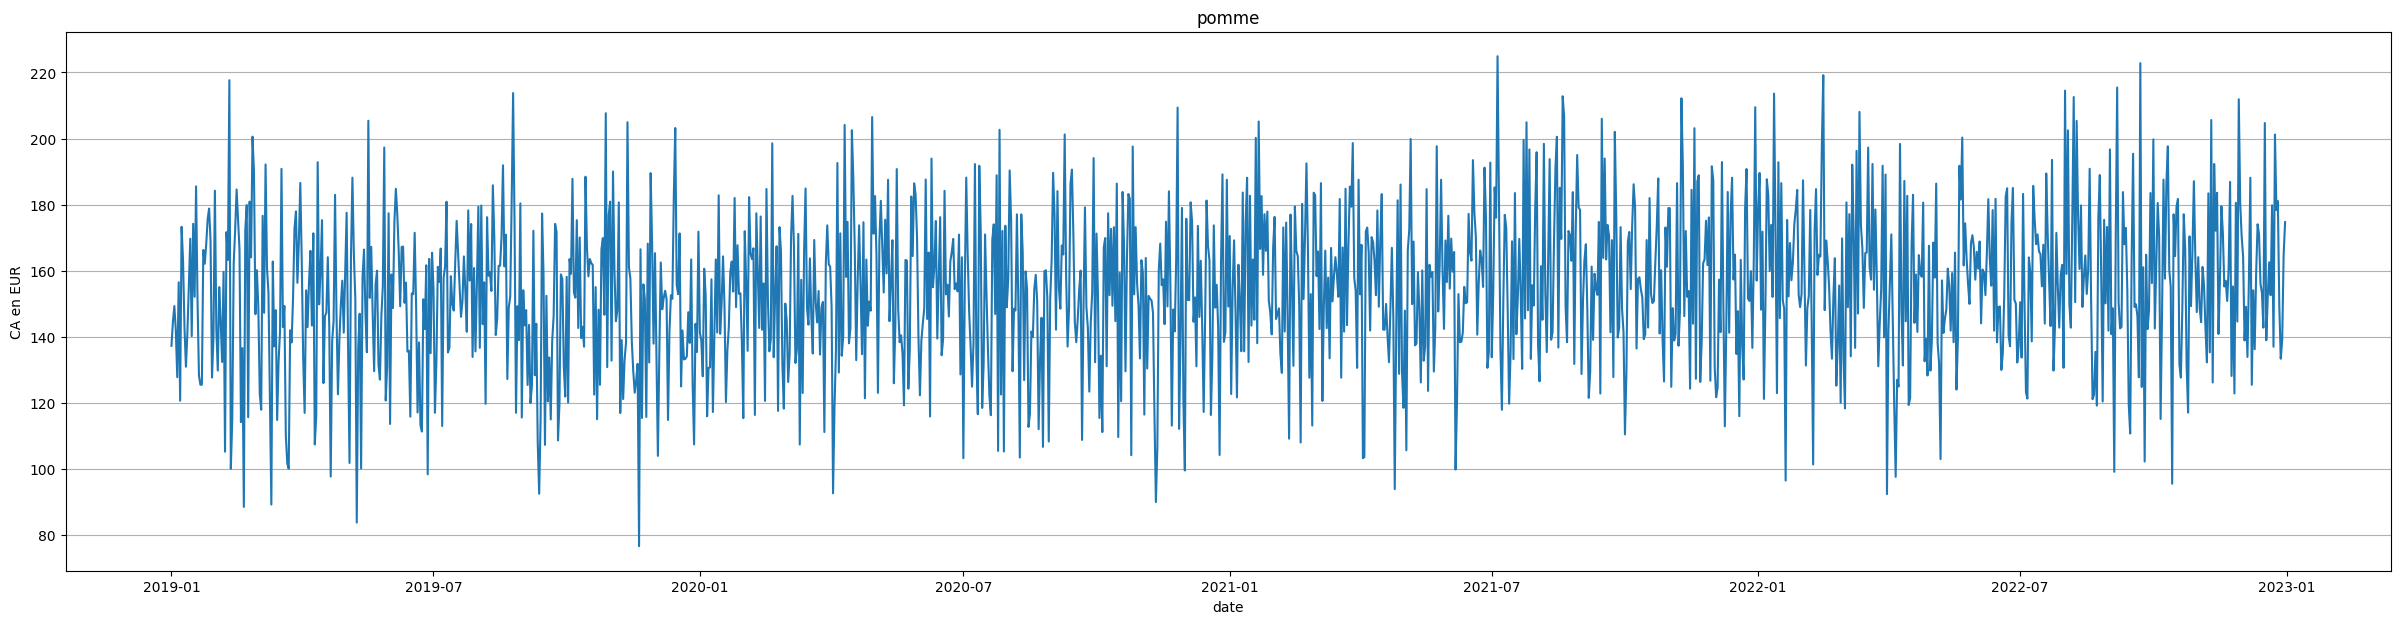

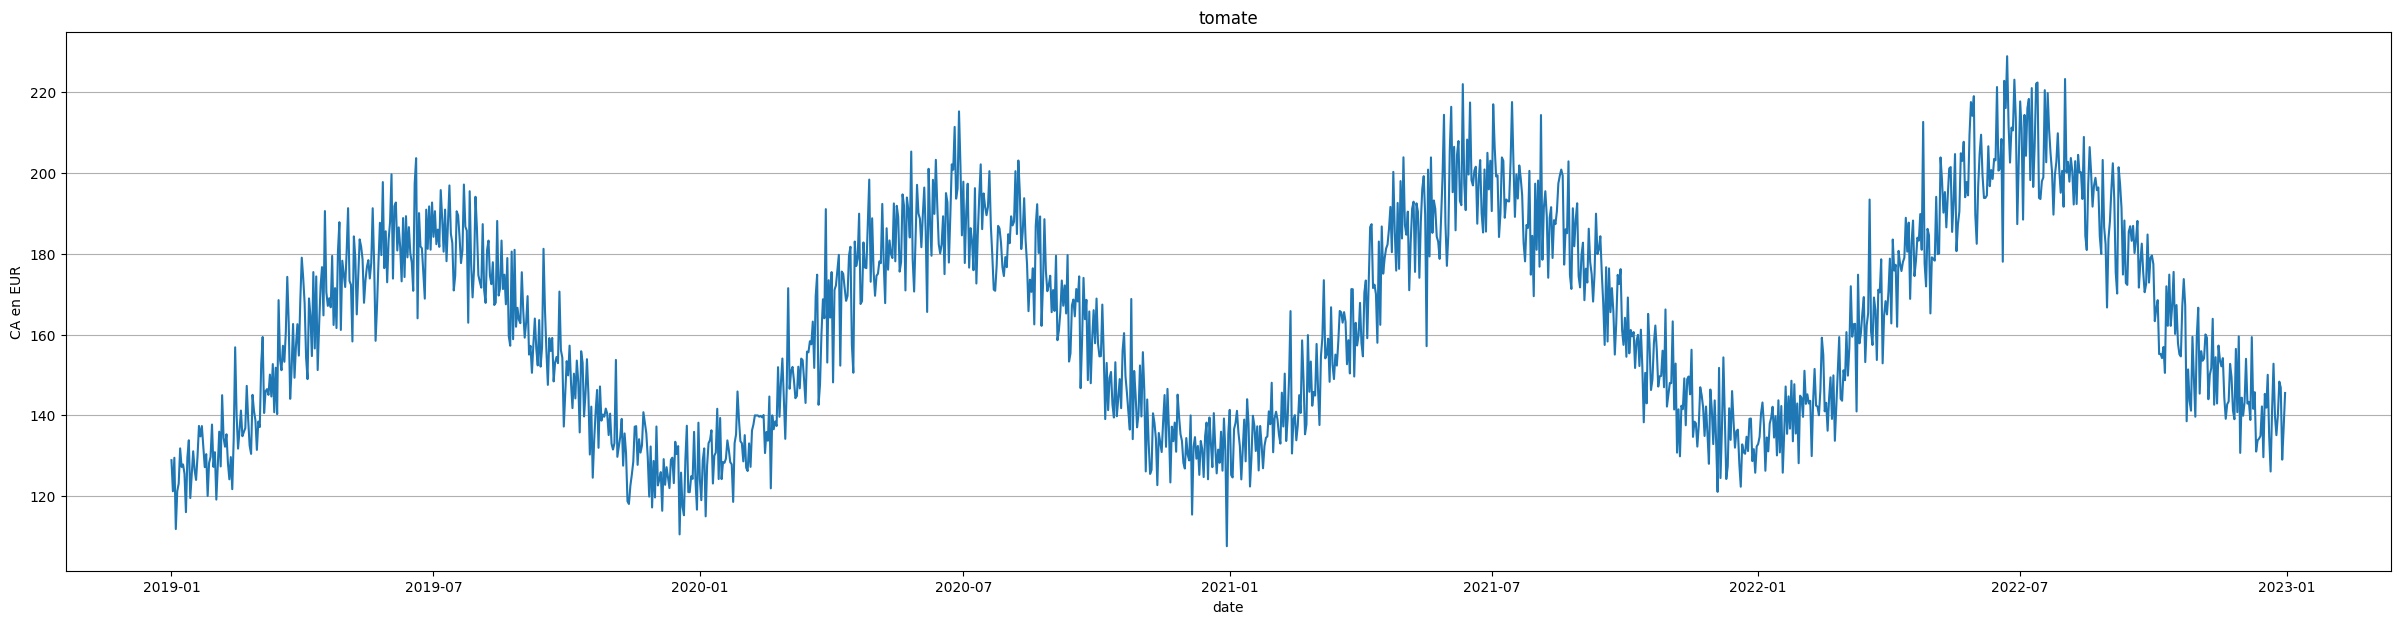

In [ ]:
#Evolution du CA par jour de 2019 à 2022 et par Produit
groups = df_top_5.groupby("product")

for product, df in groups:

    plt.figure(figsize=(30, 7))
    plt.plot(df["date"], df["sales"])
    plt.title(product)
    plt.xlabel("date")
    plt.ylabel("CA en EUR")
    plt.grid(axis="y")



*   Tomate, abricot suivent la meme saisonnalité que le data set complet, avec un motif qui se répète à l'identique chaque année : hausse du CA autour de Juillet et baisse autour de Janvier.

*   On observe pour le Kiwi une saisonnalité mais avec une hausse du CA autour de Janvier et une baisse autour de Juillet avec le même motif qui se répète chaque année.



*   Pomme et banane ne montrent pas de saisonnalité marquée, leur CA reste globalement stable tout au long de l'année.



####Analyse / an

In [ ]:
df_top_5.set_index('date',inplace=True)
df_top_5.head()

,index,product,sales,annee,mois
date,,,,,
2019-01-01,730,tomate,128.89,2019,1
2019-01-02,731,tomate,121.19,2019,1
2019-01-03,732,tomate,129.49,2019,1
2019-01-04,733,tomate,111.83,2019,1
2019-01-05,734,tomate,121.21,2019,1


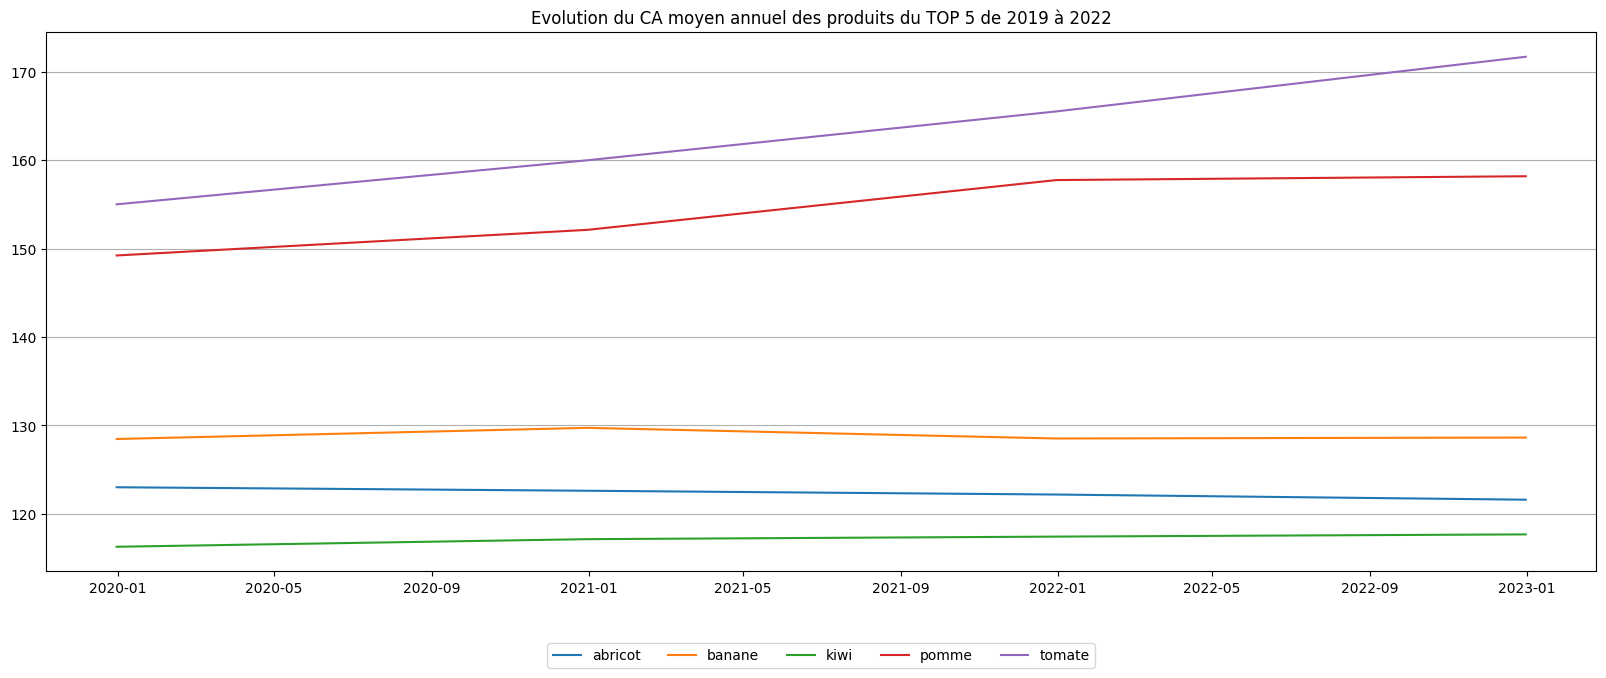

In [ ]:
#EVOLUTION DU CA du TOP 5 DE 2019 à 2022 par AN
groups = df_top_5.groupby("product")
plt.figure(figsize=(20, 7))
for product, df in groups:
    evolution_ca = df.groupby("date")["sales"].sum()
    plt.plot(evolution_ca.resample ('YE').mean(), label = product)
    plt.title('Evolution du CA moyen annuel des produits du TOP 5 de 2019 à 2022')
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5)
    plt.grid(axis ='y')
plt.show()

Le graphique montre l'évolution du CA moyen par an et par produit.

*   Tomate : hausse constante du CA
*   Pomme : tendance à la hausse jusqu'en 2021, puis stabilisation en 2022
*   Banane, Kiwi, abricot : tendance globale stable

####Analyse / mois

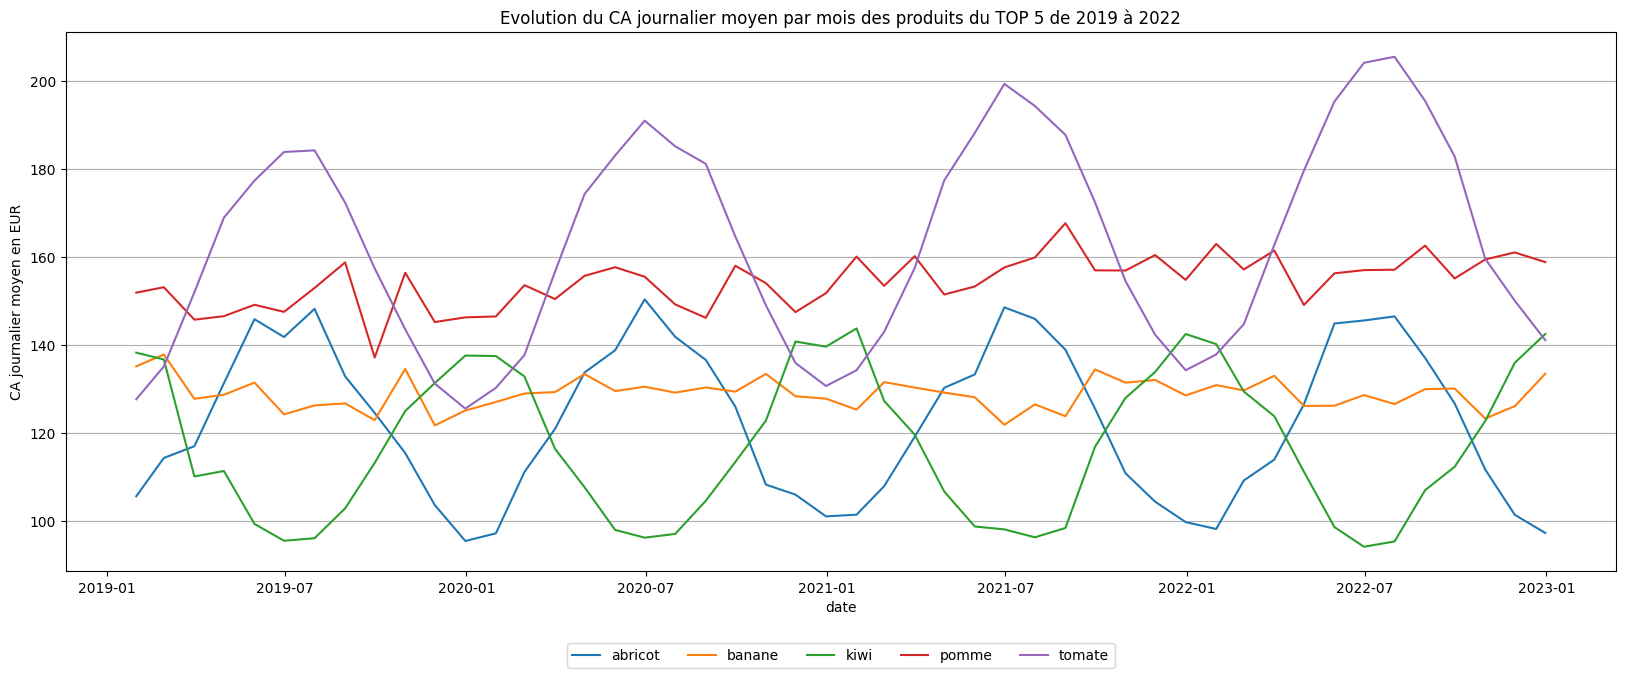

In [ ]:
#EVOLUTION DU CA du TOP 5 DE 2019 à 2022 par MOIS
groups = df_top_5.groupby("product")
plt.figure(figsize=(20, 7))
for product, df in groups:
    evolution_ca = df.groupby("date")["sales"].sum()
    plt.plot(evolution_ca.resample ('ME').mean(), label = product)
    plt.title('Evolution du CA journalier moyen par mois des produits du TOP 5 de 2019 à 2022')
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5)
    plt.xlabel("date")
    plt.ylabel("CA journalier moyen en EUR")
    plt.grid(axis ='y')
plt.show()




*   Tomate : saisonnalité visible, pic net chaque année autour de juillet et août, avec une évolution à la hausse au fil des années.
*   Abricot : saisonnalité aussi, mais le pic arrive plus tôt, autour de juin
*   Kiwi : saisonnalité inversée par rapport à tomate et abricot : le kiwi est bas en été (creux vers juillet et août) et haut en hiver (pic vers décembre et janvier)
*   Pomme et banane : profil stable, quelques variations mais pas de saisonnalités observables




### 2.4 Décomposition de la série (tendance, saisonnalité, résidu)


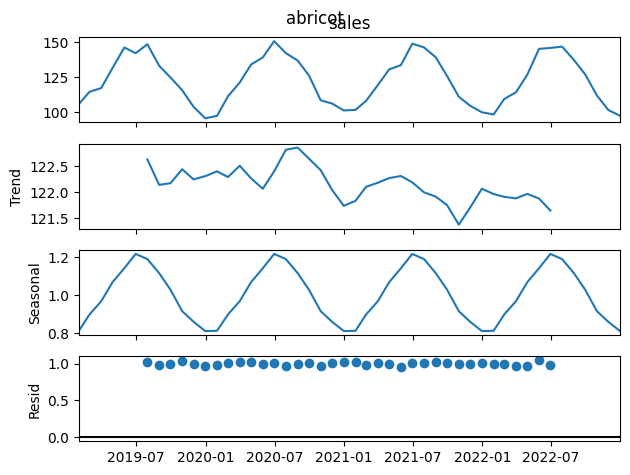

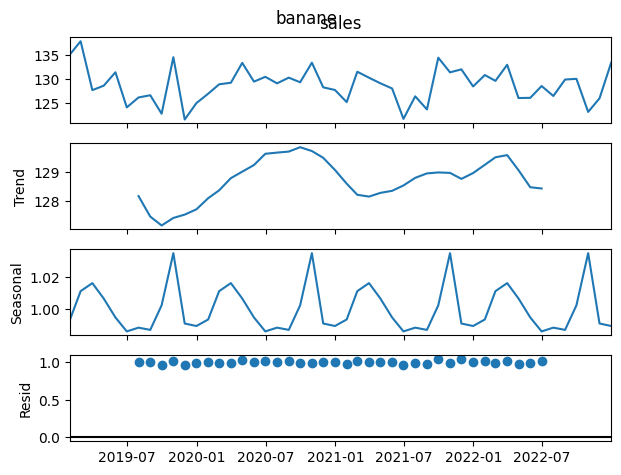

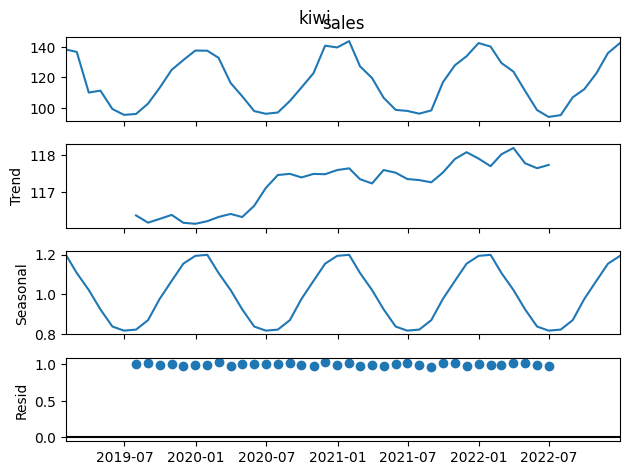

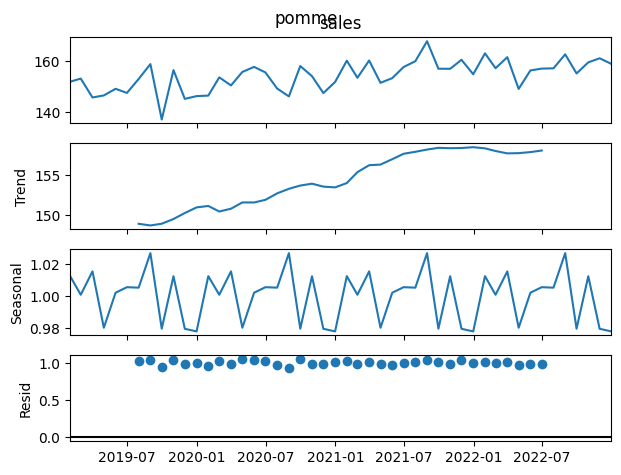

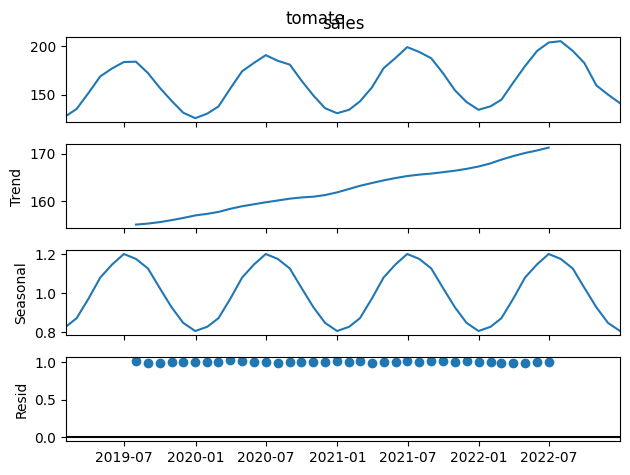

In [ ]:
groups = df_top_5.groupby("product")

for product, df in groups:
    evolution_ca = df.groupby("date")["sales"].sum()
    analyse_stl = evolution_ca.resample("ME").mean().copy()
    decompose_result_mult = seasonal_decompose(analyse_stl, model="multiplicative")

    trend = decompose_result_mult.trend
    seasonal = decompose_result_mult.seasonal
    residual = decompose_result_mult.resid

    decompose_result_mult.plot()
    plt.suptitle(product)

ABRICOT
*   Tendance global : légère tendance à la baisse du CA
*   Saisonnalité forte et régulière

BANANE
*   Tendance global : CA vente plutôt stable
*   Saisonnalité faible

KIWI
*   Tendance global : CA vente en hausse lègère
*   Saisonnalité forte et régulière

POMME
*   Tendance global : CA vente en hausse legère puis stabilisation
*   Saisonnalité faible

TOMATE
*   Tendance global : CA à la hausse et de façon constante.
*   Saisonnalité forte et régulière

RESIDU proche de 1 = tendance et saisonnalité explique bien l'évolution du CA

# 3/ Analyse comparative du CA pour les différents produits du TOP 5

### 3.1 Distribution du CA du TOP 5

#### 3.1.1 Boxplot

In [ ]:
print(df["sales"].describe())

count   1461.00
mean     163.04
std       25.13
min      107.58
25%      140.48
50%      162.56
75%      183.27
max      228.91
Name: sales, dtype: float64


In [ ]:

#plotly express
px.box(df_top_5,x="product",y="sales",title="Distribution du CA par produit du TOP 5 ")

#### 3.1.2 Calculs des outliers

In [ ]:
groups = df_top_5.groupby("product")

for product, df in groups:

    Q1 = df["sales"].quantile(0.25)
    Q3 = df["sales"].quantile(0.75)

    IQR = Q3 - Q1

    Seuil_bas = Q1 - 1.5 * IQR
    Seuil_haut = Q3 + 1.5 * IQR

    outliers = df[(df["sales"] < Seuil_bas) | (df["sales"] > Seuil_haut)]

    print(product)
    print("Nombre d'outliers :", len(outliers))
    display(outliers)

abricot
Nombre d'outliers : 3


,index,product,sales,annee,mois
date,,,,,
2019-05-30,7452,abricot,199.86,2019,5
2019-06-02,7455,abricot,198.24,2019,6
2021-07-07,8221,abricot,195.55,2021,7


banane
Nombre d'outliers : 7


,index,product,sales,annee,mois
date,,,,,
2020-04-19,5586,banane,187.62,2020,4
2020-05-24,5621,banane,183.85,2020,5
2021-01-27,5869,banane,70.69,2021,1
2021-05-30,5992,banane,186.72,2021,5
2022-04-07,6304,banane,67.45,2022,4
2022-06-05,6363,banane,187.45,2022,6
2022-08-01,6420,banane,69.64,2022,8


kiwi
Nombre d'outliers : 0


,index,product,sales,annee,mois
date,,,,,


pomme
Nombre d'outliers : 8


,index,product,sales,annee,mois
date,,,,,
2019-02-20,2971,pomme,88.49,2019,2
2019-03-11,2990,pomme,89.22,2019,3
2019-05-09,3049,pomme,83.75,2019,5
2019-11-20,3244,pomme,76.60,2019,11
2020-11-11,3601,pomme,89.95,2020,11
2021-07-05,3837,pomme,224.91,2021,7
2022-02-15,4062,pomme,219.17,2022,2
2022-09-22,4281,pomme,222.81,2022,9


tomate
Nombre d'outliers : 0


,index,product,sales,annee,mois
date,,,,,


Les valeurs atypiques restent ponctuelles par rapport à l'ensemble des observations. Ces valeurs peuvent correspondre à des pics de ventes, je décide de ne pas les supprimer

#### 3.1.3 Comparaison distribution du TOP 5 : Histogramme

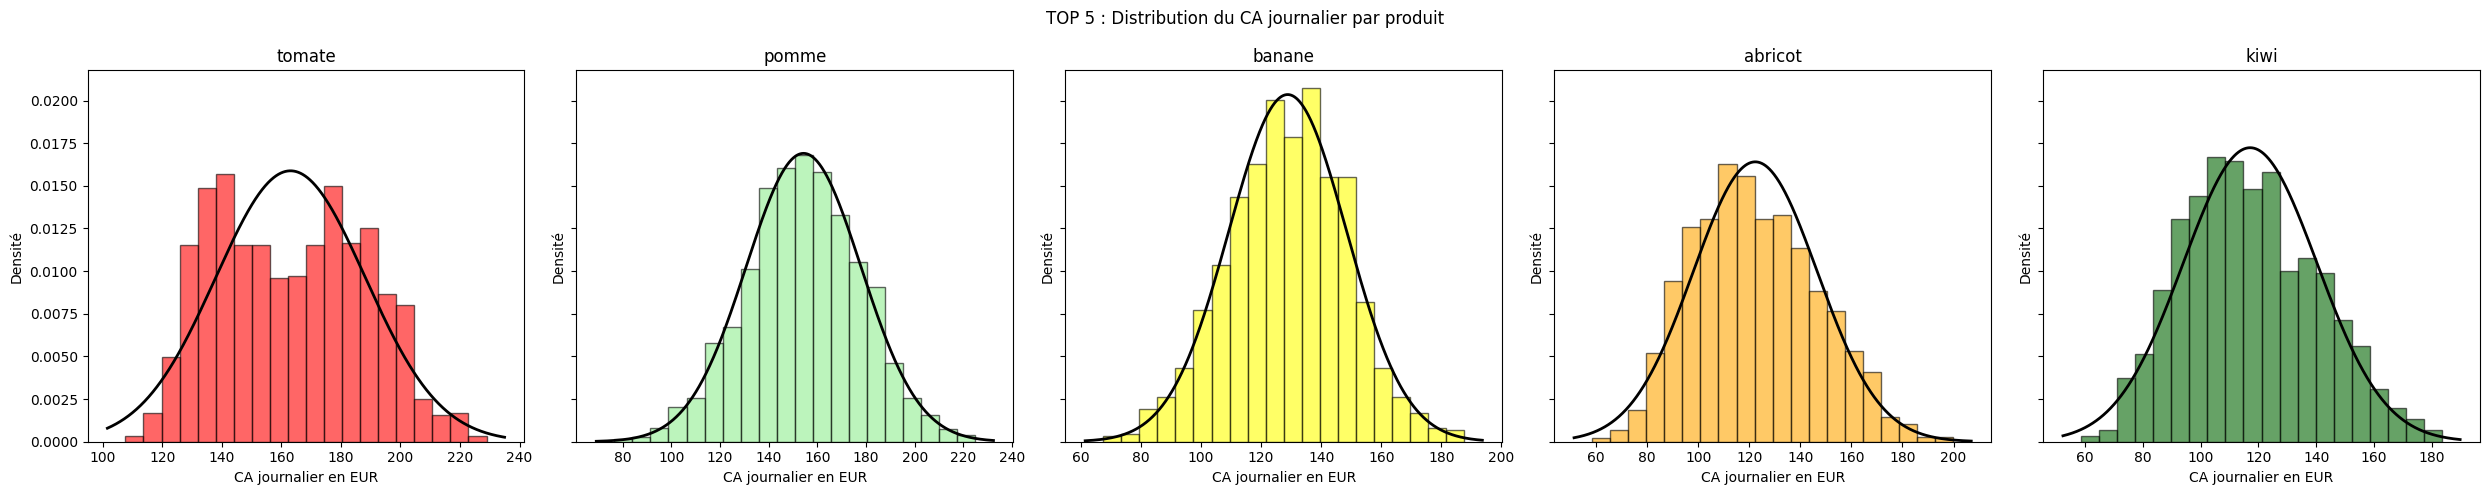

In [ ]:
groups = df_top_5.groupby("product", sort=False)

fig, axes = plt.subplots(1, 5, figsize=(25, 5), sharey=True)

colors = ['red', 'lightgreen', 'yellow', 'orange', 'darkgreen']

for (product, df), ax, color in zip(groups, axes, colors):

    ax.hist(df["sales"], bins=20, density=True, color=color, edgecolor="black", alpha=0.6)
    ax.set_title(product)
    ax.set_xlabel("CA journalier en EUR")
    ax.set_ylabel("Densité")

    # Ajustement gaussien
    mu, std = norm.fit(df["sales"])
    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, df.shape[0])
    p = norm.pdf(x, mu, std)
    ax.plot(x, p, "k", linewidth=2)

plt.suptitle("TOP 5 : Distribution du CA journalier par produit")
plt.tight_layout()
plt.show()

Observation des graphiques :
*  Tomate : distribution NON NORMALE, bimodale avec 2 pics visibles.
*  Abricot / kiwi  : distribution qui suit la courbe de Gauss avec une légère assymétrie
*  Pomme, Banane : ditribution normale gaussienne, hausse et baisse de la courbe de façon symétrique


In [ ]:
#Calul moyenne et écart-type et coef de variation
groups = df_top_5.groupby("product")
for product, df in groups:
    mean = df["sales"].mean()
    std = df["sales"].std()
    coef_variation = std / mean * 100
    print(f"Moyenne {product} : {mean:.2f}")
    print(f"Écart type {product} : {std:.2f}")
    print(f"Coefficient de variation {product} : {coef_variation:.2f}%")

Moyenne abricot : 122.36
Écart type abricot : 24.33
Coefficient de variation abricot : 19.88%
Moyenne banane : 128.84
Écart type banane : 19.61
Coefficient de variation banane : 15.22%
Moyenne kiwi : 117.14
Écart type kiwi : 23.16
Coefficient de variation kiwi : 19.77%
Moyenne pomme : 154.31
Écart type pomme : 23.61
Coefficient de variation pomme : 15.30%
Moyenne tomate : 163.04
Écart type tomate : 25.13
Coefficient de variation tomate : 15.41%


Analyse statistique de la distribution :
- Pomme et tomate ont les CA moyens les plus élevés (154.31eur et 163.04eur).
- Abricot et kiwi sont les plus variables, avec un coef de variation d’environ 20 %.
- Banane, pomme et tomate sont plus stables, autour de 15 % de variation.

Vérification de la normalité de la distribution avec le test de normalité .
Avant de réaliser tous tests, nous devons d’abord émettre deux types d’hypothèses.

- Hypothèse nulle (H0) : elle postule que les données suivent une distribution normale.

- Hypothèse alternative (H1) : elle indique que les données ne suivent pas une distribution normale.
- si p <0.05 HO est rejeté

In [ ]:
#test de normalité Shapiro-Wilk
groups = df_top_5.groupby("product")

for product, df in groups:
# Extraire la colonne 'sales'
    sales = df["sales"].dropna()
# Effectuer le test de Shapiro-Wilk
    stat, p_value = shapiro(sales)
# Afficher les résultats
    print(f"\n{product}")
    print(f"Statistique du test de Shapiro-Wilk : {stat}")
    print(f"Valeur p : {p_value}")
# Interprétation des résultats
    alpha = 0.05
    if p_value > alpha:
        print("Les données suivent une distribution normale (on ne rejette pas H0)")
    else:
        print("Les données ne suivent pas une distribution normale (on rejette H0)")


abricot
Statistique du test de Shapiro-Wilk : 0.990224633514351
Valeur p : 2.6441684634573488e-08
Les données ne suivent pas une distribution normale (on rejette H0)

banane
Statistique du test de Shapiro-Wilk : 0.9986419556337306
Valeur p : 0.31587264968737705
Les données suivent une distribution normale (on ne rejette pas H0)

kiwi
Statistique du test de Shapiro-Wilk : 0.9890749908692488
Valeur p : 5.29946092105705e-09
Les données ne suivent pas une distribution normale (on rejette H0)

pomme
Statistique du test de Shapiro-Wilk : 0.9990656585275491
Valeur p : 0.6775425958305372
Les données suivent une distribution normale (on ne rejette pas H0)

tomate
Statistique du test de Shapiro-Wilk : 0.9704361991223189
Valeur p : 9.884846722723185e-17
Les données ne suivent pas une distribution normale (on rejette H0)


Tout comme l’observation des histogrammes, le test de Shapiro-Wilk indique que les distributions de la pomme et de la banane peuvent être considérées comme normales, de type gaussien.

En revanche, contrairement à l’observation graphique, le test statistique indique que les distributions de la tomate, de l’abricot et du kiwi ne peuvent pas être considérées comme normales.

Cette vérification de la normalité va me permettre de choisir les tests de saisonnalité et de corrélation adaptés pour comparer les profils saisonniers des produits.

### 3.2 Comparaison de la saisonnalité

#### 3.2.1 Calcul du coefficiant de saisonnalité

In [ ]:
#Création des DF par Produit
df_tomate= df_top_5.loc[(df_top_5['product']==('tomate')), :]
df_pomme= df_top_5.loc[(df_top_5['product']==('pomme')), :]
df_banane= df_top_5.loc[(df_top_5['product']==('banane')), :]
df_abricot= df_top_5.loc[(df_top_5['product']==('abricot')), :]
df_kiwi= df_top_5.loc[(df_top_5['product']==('kiwi')), :]

In [ ]:
#Indicateur coef saisonnalité TOMATE
df_tomate_analyse_mois = df_tomate.pivot_table( index = "annee", columns='mois', values= 'sales',aggfunc='mean')
df_tomate_analyse_mois['Moyenne_année'] = (df_tomate_analyse_mois[1]+df_tomate_analyse_mois[2]+df_tomate_analyse_mois[3]+df_tomate_analyse_mois[4]+df_tomate_analyse_mois[5]+df_tomate_analyse_mois[6]+df_tomate_analyse_mois[7]+df_tomate_analyse_mois[8]+df_tomate_analyse_mois[9]+df_tomate_analyse_mois[10]+df_tomate_analyse_mois[11]+df_tomate_analyse_mois[12])/12
df_tomate_analyse_mois.loc['Moyenne_mois'] = (df_tomate_analyse_mois.loc[2019] + df_tomate_analyse_mois.loc[2020] + df_tomate_analyse_mois.loc[2021] + df_tomate_analyse_mois.loc[2022]) / 4
Moyenne_annuelle_4ans = df_tomate_analyse_mois['Moyenne_année'].mean()
print(Moyenne_annuelle_4ans)
df_tomate_analyse_mois.loc['Coef_saisonnier'] = df_tomate_analyse_mois.loc['Moyenne_mois'] / (Moyenne_annuelle_4ans)
df_tomate_analyse_mois.head(10)

162.94589049529762


mois,1,2,3,4,5,6,7,8,9,10,11,12,Moyenne_année
annee,,,,,,,,,,,,,
2019,127.63,135.08,151.93,168.91,177.33,183.83,184.20,172.33,157.37,143.51,131.18,125.49,154.90
2020,130.23,137.67,156.62,174.27,183.03,190.95,185.11,181.14,164.62,148.99,135.88,130.65,159.93
2021,134.22,142.93,157.45,177.38,188.16,199.31,194.29,187.72,172.41,154.48,142.31,134.22,165.41
2022,137.81,144.68,162.72,179.59,195.30,204.11,205.47,195.43,182.80,159.57,150.03,141.05,171.55
Moyenne_mois,132.47,140.09,157.18,175.04,185.96,194.55,192.27,184.16,169.30,151.64,139.85,132.85,162.95
Coef_saisonnier,0.81,0.86,0.96,1.07,1.14,1.19,1.18,1.13,1.04,0.93,0.86,0.82,1.00


In [ ]:
#Indicateur coef saisonnalité POMME
df_pomme_analyse_mois = df_pomme.pivot_table( index = "annee", columns='mois', values= 'sales',aggfunc='mean')
df_pomme_analyse_mois['Moyenne_année'] = (df_pomme_analyse_mois[1]+df_pomme_analyse_mois[2]+df_pomme_analyse_mois[3]+df_pomme_analyse_mois[4]+df_pomme_analyse_mois[5]+df_pomme_analyse_mois[6]+df_pomme_analyse_mois[7]+df_pomme_analyse_mois[8]+df_pomme_analyse_mois[9]+df_pomme_analyse_mois[10]+df_pomme_analyse_mois[11]+df_pomme_analyse_mois[12])/12
df_pomme_analyse_mois.loc['Moyenne_mois'] = (df_pomme_analyse_mois.loc[2019] + df_pomme_analyse_mois.loc[2020] + df_pomme_analyse_mois.loc[2021] + df_pomme_analyse_mois.loc[2022]) / 4
Moyenne_annuelle_4ans = df_pomme_analyse_mois['Moyenne_année'].mean()
print(Moyenne_annuelle_4ans)
df_pomme_analyse_mois.loc['Coef_saisonnier'] = df_pomme_analyse_mois.loc['Moyenne_mois'] / (Moyenne_annuelle_4ans)
df_pomme_analyse_mois.head(10)

154.29474045837523


mois,1,2,3,4,5,6,7,8,9,10,11,12,Moyenne_année
annee,,,,,,,,,,,,,
2019,151.86,153.09,145.72,146.51,149.10,147.49,152.93,158.73,137.12,156.38,145.17,146.24,149.20
2020,146.45,153.56,150.41,155.68,157.64,155.48,149.18,146.14,157.97,154.02,147.44,151.75,152.14
2021,160.05,153.40,160.14,151.43,153.26,157.59,159.86,167.64,156.93,156.89,160.41,154.76,157.70
2022,162.93,157.13,161.43,149.05,156.25,156.98,157.07,162.55,155.09,159.41,161.00,158.81,158.14
Moyenne_mois,155.32,154.30,154.42,150.67,154.06,154.39,154.76,158.76,151.78,156.68,153.50,152.89,154.29
Coef_saisonnier,1.01,1.00,1.00,0.98,1.00,1.00,1.00,1.03,0.98,1.02,0.99,0.99,1.00


In [ ]:
#Indicateur coef saisonnalité BANANE
df_banane_analyse_mois = df_banane.pivot_table( index = "annee", columns='mois', values= 'sales',aggfunc='mean')
df_banane_analyse_mois['Moyenne_année'] = (df_banane_analyse_mois[1]+df_banane_analyse_mois[2]+df_banane_analyse_mois[3]+df_banane_analyse_mois[4]+df_banane_analyse_mois[5]+df_banane_analyse_mois[6]+df_banane_analyse_mois[7]+df_banane_analyse_mois[8]+df_banane_analyse_mois[9]+df_banane_analyse_mois[10]+df_banane_analyse_mois[11]+df_banane_analyse_mois[12])/12
df_banane_analyse_mois.loc['Moyenne_mois'] = (df_banane_analyse_mois.loc[2019] + df_banane_analyse_mois.loc[2020] + df_banane_analyse_mois.loc[2021] + df_banane_analyse_mois.loc[2022]) / 4
Moyenne_annuelle_4ans = df_banane_analyse_mois['Moyenne_année'].mean()
print(Moyenne_annuelle_4ans)
df_banane_analyse_mois.loc['Coef_saisonnier'] = df_banane_analyse_mois.loc['Moyenne_mois'] / (Moyenne_annuelle_4ans)
df_banane_analyse_mois.head(10)

128.8556636081825


mois,1,2,3,4,5,6,7,8,9,10,11,12,Moyenne_année
annee,,,,,,,,,,,,,
2019,135.12,137.80,127.74,128.65,131.41,124.19,126.23,126.69,122.88,134.52,121.69,125.07,128.50
2020,127.00,128.94,129.26,133.35,129.49,130.48,129.14,130.31,129.36,133.39,128.31,127.77,129.73
2021,125.27,131.53,130.29,129.14,128.08,121.82,126.46,123.77,134.41,131.40,132.02,128.50,128.56
2022,130.85,129.65,132.96,126.11,126.15,128.58,126.54,129.92,130.07,123.25,126.05,133.44,128.63
Moyenne_mois,129.56,131.98,130.06,129.31,128.79,126.27,127.09,127.67,129.18,130.64,127.02,128.70,128.86
Coef_saisonnier,1.01,1.02,1.01,1.00,1.00,0.98,0.99,0.99,1.00,1.01,0.99,1.00,1.00


In [ ]:
#Indicateur coef saisonnalité ABRICOT
df_abricot_analyse_mois = df_abricot.pivot_table( index = "annee", columns='mois', values= 'sales',aggfunc='mean')
df_abricot_analyse_mois['Moyenne_année'] = (df_abricot_analyse_mois[1]+df_abricot_analyse_mois[2]+df_abricot_analyse_mois[3]+df_abricot_analyse_mois[4]+df_abricot_analyse_mois[5]+df_abricot_analyse_mois[6]+df_abricot_analyse_mois[7]+df_abricot_analyse_mois[8]+df_abricot_analyse_mois[9]+df_abricot_analyse_mois[10]+df_abricot_analyse_mois[11]+df_abricot_analyse_mois[12])/12
df_abricot_analyse_mois.loc['Moyenne_mois'] = (df_abricot_analyse_mois.loc[2019] + df_abricot_analyse_mois.loc[2020] + df_abricot_analyse_mois.loc[2021] + df_abricot_analyse_mois.loc[2022]) / 4
Moyenne_annuelle_4ans = df_abricot_analyse_mois['Moyenne_année'].mean()
print(Moyenne_annuelle_4ans)
df_abricot_analyse_mois.loc['Coef_saisonnier'] = df_abricot_analyse_mois.loc['Moyenne_mois'] / (Moyenne_annuelle_4ans)
df_abricot_analyse_mois.head(10)

122.31574031386735


mois,1,2,3,4,5,6,7,8,9,10,11,12,Moyenne_année
annee,,,,,,,,,,,,,
2019,105.57,114.29,116.96,131.29,145.82,141.77,148.17,132.83,124.53,115.39,103.57,95.42,122.97
2020,97.16,111.11,120.89,133.72,138.76,150.32,141.81,136.58,125.95,108.24,105.95,101.01,122.62
2021,101.40,107.87,119.09,130.24,133.27,148.52,145.91,138.88,125.51,110.79,104.36,99.71,122.13
2022,98.14,109.16,113.92,126.48,144.84,145.54,146.47,137.03,126.67,111.67,101.37,97.23,121.54
Moyenne_mois,100.57,110.61,117.71,130.43,140.68,146.54,145.59,136.33,125.67,111.52,103.81,98.34,122.32
Coef_saisonnier,0.82,0.90,0.96,1.07,1.15,1.20,1.19,1.11,1.03,0.91,0.85,0.80,1.00


In [ ]:
#Indicateur coef saisonnalité KIWI
df_kiwi_analyse_mois = df_kiwi.pivot_table( index = "annee", columns='mois', values= 'sales',aggfunc='mean')
df_kiwi_analyse_mois['Moyenne_année'] = (df_kiwi_analyse_mois[1]+df_kiwi_analyse_mois[2]+df_kiwi_analyse_mois[3]+df_kiwi_analyse_mois[4]+df_kiwi_analyse_mois[5]+df_kiwi_analyse_mois[6]+df_kiwi_analyse_mois[7]+df_kiwi_analyse_mois[8]+df_kiwi_analyse_mois[9]+df_kiwi_analyse_mois[10]+df_kiwi_analyse_mois[11]+df_kiwi_analyse_mois[12])/12
df_kiwi_analyse_mois.loc['Moyenne_mois'] = (df_kiwi_analyse_mois.loc[2019] + df_kiwi_analyse_mois.loc[2020] + df_kiwi_analyse_mois.loc[2021] + df_kiwi_analyse_mois.loc[2022]) / 4
Moyenne_annuelle_4ans = df_kiwi_analyse_mois['Moyenne_année'].mean()
print(Moyenne_annuelle_4ans)
df_kiwi_analyse_mois.loc['Coef_saisonnier'] = df_kiwi_analyse_mois.loc['Moyenne_mois'] / (Moyenne_annuelle_4ans)
df_kiwi_analyse_mois.head(10)

117.20446897452749


mois,1,2,3,4,5,6,7,8,9,10,11,12,Moyenne_année
annee,,,,,,,,,,,,,
2019,138.22,136.67,110.08,111.32,99.30,95.47,96.05,102.83,113.17,124.96,131.32,137.56,116.41
2020,137.45,132.80,116.36,107.63,97.94,96.17,97.03,104.55,113.39,122.75,140.75,139.58,117.20
2021,143.73,127.26,119.59,106.66,98.72,98.05,96.26,98.37,116.82,127.95,133.82,142.46,117.47
2022,140.16,129.39,123.76,111.17,98.57,94.10,95.32,106.95,112.29,122.67,135.92,142.48,117.73
Moyenne_mois,139.89,131.53,117.45,109.19,98.63,95.95,96.16,103.18,113.92,124.58,135.45,140.52,117.20
Coef_saisonnier,1.19,1.12,1.00,0.93,0.84,0.82,0.82,0.88,0.97,1.06,1.16,1.20,1.00


In [ ]:
#Regroupement en un DF des coef saisonnier de chaque produit

df_coef_saisonnier_tomate = df_tomate_analyse_mois.loc['Coef_saisonnier']
df_coef_saisonnier_tomate = df_coef_saisonnier_tomate.drop(index='Moyenne_année')
df_coef_saisonnier_pomme = df_pomme_analyse_mois.loc['Coef_saisonnier']
df_coef_saisonnier_pomme = df_coef_saisonnier_pomme.drop(index='Moyenne_année')
df_coef_saisonnier_banane = df_banane_analyse_mois.loc['Coef_saisonnier']
df_coef_saisonnier_banane = df_coef_saisonnier_banane.drop(index='Moyenne_année')
df_coef_saisonnier_abricot = df_abricot_analyse_mois.loc['Coef_saisonnier']
df_coef_saisonnier_abricot = df_coef_saisonnier_abricot.drop(index='Moyenne_année')
df_coef_saisonnier_kiwi = df_kiwi_analyse_mois.loc['Coef_saisonnier']
df_coef_saisonnier_kiwi= df_coef_saisonnier_kiwi.drop(index='Moyenne_année')


df_coef_saisonnier = pd.concat([df_coef_saisonnier_tomate, df_coef_saisonnier_pomme, df_coef_saisonnier_banane,  df_coef_saisonnier_abricot, df_coef_saisonnier_kiwi], axis=1).T

df_coef_saisonnier.index = ['Tomate', 'Pomme', 'Banane', 'Abricot', 'Kiwi']
df_coef_saisonnier

mois,1,2,3,4,5,6,7,8,9,10,11,12
Tomate,0.81,0.86,0.96,1.07,1.14,1.19,1.18,1.13,1.04,0.93,0.86,0.82
Pomme,1.01,1.00,1.00,0.98,1.00,1.00,1.00,1.03,0.98,1.02,0.99,0.99
Banane,1.01,1.02,1.01,1.00,1.00,0.98,0.99,0.99,1.00,1.01,0.99,1.00
Abricot,0.82,0.90,0.96,1.07,1.15,1.20,1.19,1.11,1.03,0.91,0.85,0.80
Kiwi,1.19,1.12,1.00,0.93,0.84,0.82,0.82,0.88,0.97,1.06,1.16,1.20


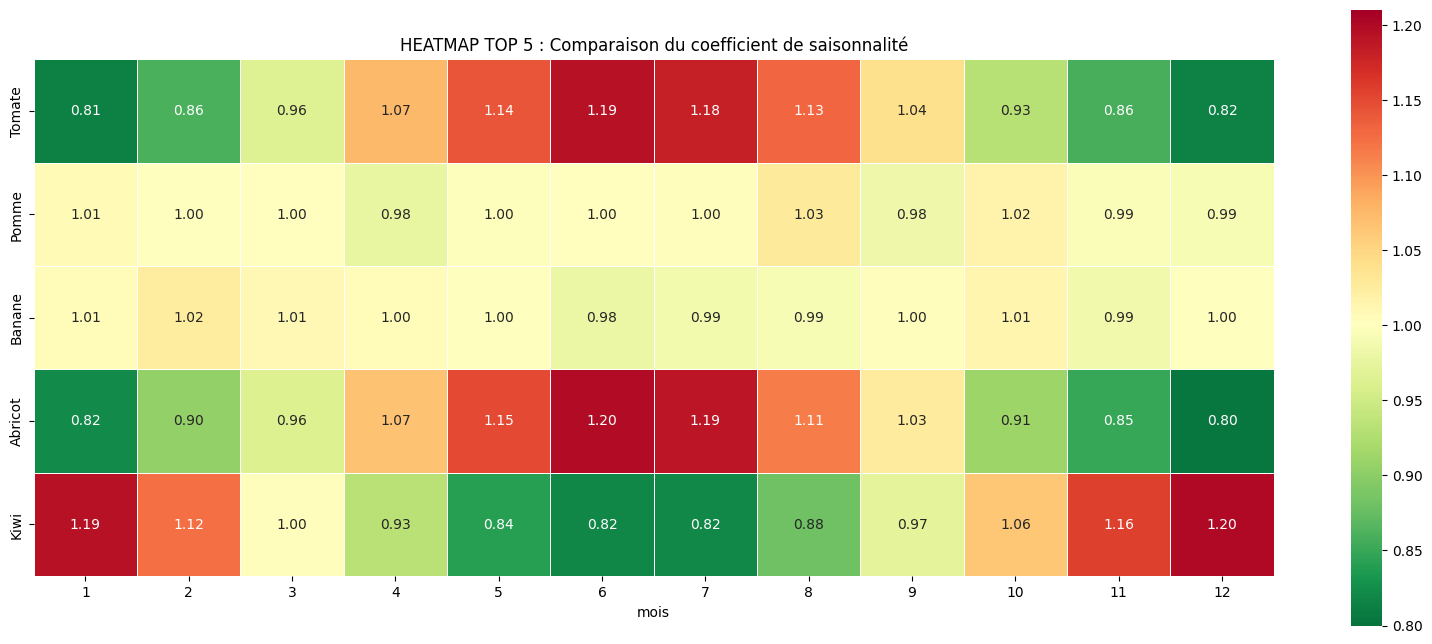

In [ ]:
#visualisation des coef de saisonnalité
plt.figure(figsize = (20,8))
sns.heatmap(data=df_coef_saisonnier, cmap = 'RdYlGn_r', vmin = 0.8, vmax = 1.21, center = 1, annot=True, fmt=".2f", square=True, linewidths=.5)
plt.title("HEATMAP TOP 5 : Comparaison du coefficient de saisonnalité")
plt.show()

coefficient saisonnier : moyenne mensuelle du CA comparée à la moyenne annuelle du produit.

Coef proche de 1 =  faible saisonnalité

*   Tomate, Abricot : forte saisonnalité, le coef varie entre 0.80 et 1.20 avec pic en été.

*   Kiwi : forte saisonnalité, le coef varie entre 0.82 et 1.20 mais le pic est en hiver et le creux en été (à l'inverse de la tomate et l'abricot)

*   Pomme et banane : saisonnalité faible (coef de 0.98 à 1.03), le CA est presque le même toute l'année


la Heatmap confirme que Tomate et abricot ont leur pic ensemble en été, le kiwi en hiver, pomme et banane sont stables


#### 3.2.2 Test de saisonnalité

- Vérifions cette observation de la saisonnalité avec le test ANOVA pour la pomme et la banane (distributions normales),
et le test de Kruskal-Wallis pour la tomate, l'abricot et le kiwi (distributions non normales).
- Vérification de la valeur p : si la valeur p est inférieure à 0.05, on rejette l'hypothèse nulle, indiquant une différence statistiquement significative entre les groupes.

In [ ]:
#Test ANOVA Pomme
from scipy.stats import f_oneway

# Sélectionner les ventes de chaque mois
janvier = df_pomme[df_pomme['mois'] == 1]['sales'].dropna()
fevrier = df_pomme[df_pomme['mois'] == 2]['sales'].dropna()
mars = df_pomme[df_pomme['mois'] == 3]['sales'].dropna()
avril = df_pomme[df_pomme['mois'] == 4]['sales'].dropna()
mai = df_pomme[df_pomme['mois'] == 5]['sales'].dropna()
juin = df_pomme[df_pomme['mois'] == 6]['sales'].dropna()
juillet = df_pomme[df_pomme['mois'] == 7]['sales'].dropna()
aout = df_pomme[df_pomme['mois'] == 8]['sales'].dropna()
septembre = df_pomme[df_pomme['mois'] == 9]['sales'].dropna()
octobre = df_pomme[df_pomme['mois'] == 10]['sales'].dropna()
novembre = df_pomme[df_pomme['mois'] == 11]['sales'].dropna()
decembre = df_pomme[df_pomme['mois'] == 12]['sales'].dropna()

# Test ANOVA
f_stat, p_value = f_oneway(janvier, fevrier, mars, avril, mai, juin,juillet, aout, septembre, octobre, novembre, decembre)

print(f"Statistique F Pomme : {f_stat:.2f}")
print(f"Valeur p : {p_value:.3f}")

Statistique F Pomme : 0.98
Valeur p : 0.463


In [ ]:
#Test ANOVA Banane


# Sélectionner les ventes de chaque mois
janvier = df_banane[df_banane['mois'] == 1]['sales'].dropna()
fevrier = df_banane[df_banane['mois'] == 2]['sales'].dropna()
mars = df_banane[df_banane['mois'] == 3]['sales'].dropna()
avril = df_banane[df_banane['mois'] == 4]['sales'].dropna()
mai = df_banane[df_banane['mois'] == 5]['sales'].dropna()
juin = df_banane[df_banane['mois'] == 6]['sales'].dropna()
juillet = df_banane[df_banane['mois'] == 7]['sales'].dropna()
aout = df_banane[df_banane['mois'] == 8]['sales'].dropna()
septembre = df_banane[df_banane['mois'] == 9]['sales'].dropna()
octobre = df_banane[df_banane['mois'] == 10]['sales'].dropna()
novembre = df_banane[df_banane['mois'] == 11]['sales'].dropna()
decembre = df_banane[df_banane['mois'] == 12]['sales'].dropna()

# Test ANOVA
f_stat, p_value = f_oneway(janvier, fevrier, mars, avril, mai, juin,juillet, aout, septembre, octobre, novembre, decembre)

print(f"Statistique F Banane : {f_stat:.2f}")
print(f"Valeur p : {p_value:.3f}")

Statistique F Banane : 0.83
Valeur p : 0.607


Pour Pomme et Banane valeur p >0.05, le test ANOVA indique qu'il n y' a pas de différence significative entre les mois.

In [ ]:
from scipy.stats import kruskal
# Test Kruskal-Wallis Tomate

# Sélectionner les ventes de chaque mois
janvier = df_tomate[df_tomate['mois'] == 1]['sales'].dropna()
fevrier = df_tomate[df_tomate['mois'] == 2]['sales'].dropna()
mars = df_tomate[df_tomate['mois'] == 3]['sales'].dropna()
avril = df_tomate[df_tomate['mois'] == 4]['sales'].dropna()
mai = df_tomate[df_tomate['mois'] == 5]['sales'].dropna()
juin = df_tomate[df_tomate['mois'] == 6]['sales'].dropna()
juillet = df_tomate[df_tomate['mois'] == 7]['sales'].dropna()
aout = df_tomate[df_tomate['mois'] == 8]['sales'].dropna()
septembre = df_tomate[df_tomate['mois'] == 9]['sales'].dropna()
octobre = df_tomate[df_tomate['mois'] == 10]['sales'].dropna()
novembre = df_tomate[df_tomate['mois'] == 11]['sales'].dropna()
decembre = df_tomate[df_tomate['mois'] == 12]['sales'].dropna()

# Test Kruskal-Wallis
h_stat, p_value = kruskal(janvier, fevrier, mars, avril, mai, juin,juillet, aout, septembre, octobre, novembre, decembre)

print(f"Tomate par mois : H = {h_stat:.2f}, p = {p_value:.3e}")

Tomate par mois : H = 1189.98, p = 2.342e-248


In [ ]:
# Test Kruskal-Wallis Abricot

# Sélectionner les ventes de chaque mois
janvier = df_abricot[df_abricot['mois'] == 1]['sales'].dropna()
fevrier = df_abricot[df_abricot['mois'] == 2]['sales'].dropna()
mars = df_abricot[df_abricot['mois'] == 3]['sales'].dropna()
avril = df_abricot[df_abricot['mois'] == 4]['sales'].dropna()
mai = df_abricot[df_abricot['mois'] == 5]['sales'].dropna()
juin = df_abricot[df_abricot['mois'] == 6]['sales'].dropna()
juillet = df_abricot[df_abricot['mois'] == 7]['sales'].dropna()
aout = df_abricot[df_abricot['mois'] == 8]['sales'].dropna()
septembre = df_abricot[df_abricot['mois'] == 9]['sales'].dropna()
octobre = df_abricot[df_abricot['mois'] == 10]['sales'].dropna()
novembre = df_abricot[df_abricot['mois'] == 11]['sales'].dropna()
decembre = df_abricot[df_abricot['mois'] == 12]['sales'].dropna()

# Test Kruskal-Wallis
h_stat, p_value = kruskal(janvier, fevrier, mars, avril, mai, juin,juillet, aout, septembre, octobre, novembre, decembre)

print(f"Abricot par mois : H = {h_stat:.2f}, p = {p_value:.3e}")

Abricot par mois : H = 728.23, p = 4.780e-149


In [ ]:
# Test Kruskal-Wallis Kiwi

# Sélectionner les ventes de chaque mois
janvier = df_kiwi[df_kiwi['mois'] == 1]['sales'].dropna()
fevrier = df_kiwi[df_kiwi['mois'] == 2]['sales'].dropna()
mars = df_kiwi[df_kiwi['mois'] == 3]['sales'].dropna()
avril = df_kiwi[df_kiwi['mois'] == 4]['sales'].dropna()
mai = df_kiwi[df_kiwi['mois'] == 5]['sales'].dropna()
juin = df_kiwi[df_kiwi['mois'] == 6]['sales'].dropna()
juillet = df_kiwi[df_kiwi['mois'] == 7]['sales'].dropna()
aout = df_kiwi[df_kiwi['mois'] == 8]['sales'].dropna()
septembre = df_kiwi[df_kiwi['mois'] == 9]['sales'].dropna()
octobre = df_kiwi[df_kiwi['mois'] == 10]['sales'].dropna()
novembre = df_kiwi[df_kiwi['mois'] == 11]['sales'].dropna()
decembre = df_kiwi[df_kiwi['mois'] == 12]['sales'].dropna()

# Test Kruskal-Wallis
h_stat, p_value = kruskal(janvier, fevrier, mars, avril, mai, juin,juillet, aout, septembre, octobre, novembre, decembre)

print(f"Kiwi par mois : H = {h_stat:.2f}, p = {p_value:.3e}")

Kiwi par mois : H = 741.85, p = 5.718e-152


Pour Tomate, Abricot et Kiwi le test de Kruskal-Wallis indique une valeur p < à 0.05 pour les 3 produits. Les tests sont significatifs, on peut conclure que les distributions de CA diffèrent significativement selon les mois. Cela confirme un profil saisonnier pour ces 3 produits et un profil stable pour Pomme et banane.

#### 3.2.3 Test de corrélation

Vérification des conclusions de la heatmap avec les tests de corrélation

l'objectif est de prévoir une répartition de stock optimale : c'est-à-dire indiquer les produits à placer côte à côte dans l’entrepôt dans l’année

- Test de Pearson pour la pomme et la banane (distributions normales).
- Test de Spearman pour la tomate, l'abricot et le kiwi (distributions non normales).

Coefficient de corrélation de Pearson : -0.034
Valeur p : 1.99e-01


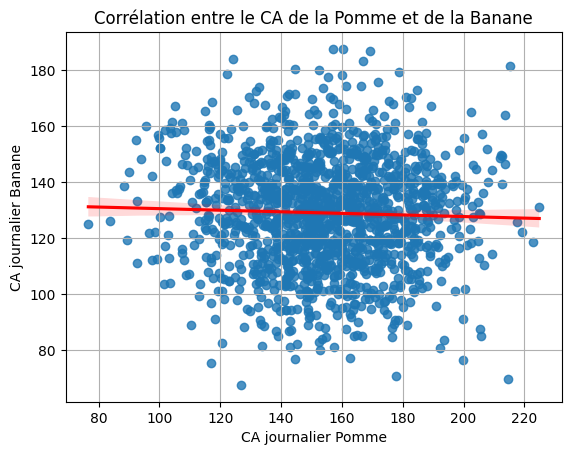

In [ ]:
# Pearson : Pomme / Banane


# Données
pomme = df_pomme['sales']
banane = df_banane['sales']

# Visualisation de la tendance
sns.regplot(x=pomme,y=banane,robust=True,line_kws=dict(color="r"))

plt.xlabel("CA journalier Pomme")
plt.ylabel("CA journalier Banane")
plt.title("Corrélation entre le CA de la Pomme et de la Banane")
plt.grid()

# Test corrélation
correlation, p_value = pearsonr(df_pomme['sales'].values, df_banane['sales'].values)
print(f"Coefficient de corrélation de Pearson : {correlation:.3f}")
print(f"Valeur p : {p_value:.2e}")

Coefficient de corrélation de Spearman : 0.648
Valeur p : 1.63e-174


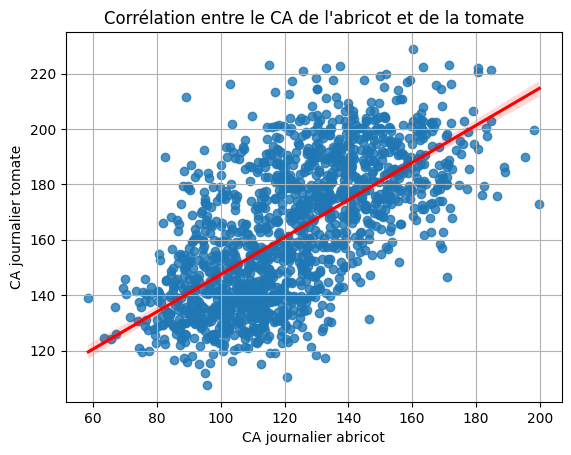

In [ ]:
# Spearman : Abricot / Tomate


# Données
abricot = df_abricot['sales']
tomate = df_tomate['sales']

# Visualisation de la tendance
sns.regplot( x=abricot,y=tomate, robust=True,line_kws=dict(color="r"))

plt.xlabel("CA journalier abricot")
plt.ylabel("CA journalier tomate")
plt.title("Corrélation entre le CA de l'abricot et de la tomate")
plt.grid()

# Test corrélation
correlation, p_value = spearmanr(df_tomate['sales'].values, df_abricot['sales'].values)
print(f"Coefficient de corrélation de Spearman : {correlation:.3f}")
print(f"Valeur p : {p_value:.2e}")

Coefficient de corrélation de Spearman : -0.655
Valeur p : 9.36e-180


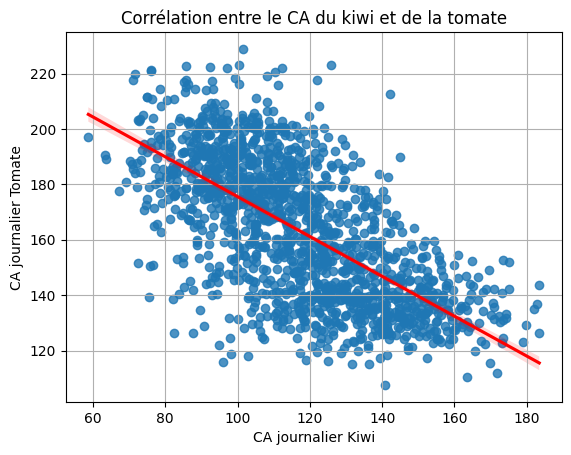

In [ ]:
# Spearman : Kiwi / Tomate

# Données
kiwi = df_kiwi['sales']
tomate = df_tomate['sales']

# Visualisation de la tendance
sns.regplot( x=kiwi,y=tomate, robust=True,line_kws=dict(color="r"))

plt.xlabel("CA journalier Kiwi")
plt.ylabel("CA journalier Tomate")
plt.title("Corrélation entre le CA du kiwi et de la tomate")
plt.grid()

correlation, p_value = spearmanr(df_kiwi['sales'].values, df_tomate['sales'].values)
print(f"Coefficient de corrélation de Spearman : {correlation:.3f}")
print(f"Valeur p : {p_value:.2e}")

Coefficient de corrélation de Spearman : -0.512
Valeur p : 2.98e-98


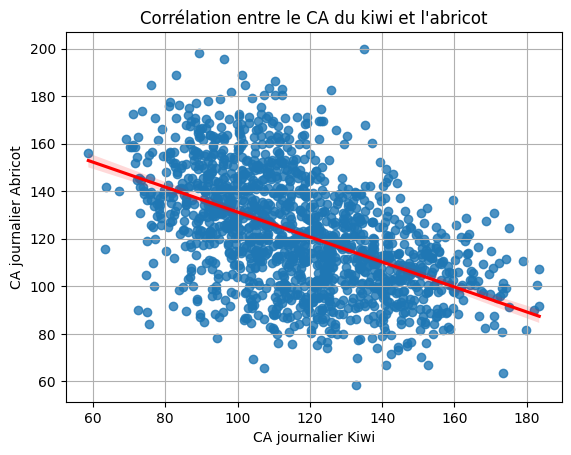

In [ ]:
# Spearman : Kiwi / Abricot

# Données
kiwi = df_kiwi['sales']
abricot = df_abricot['sales']

# Visualisation de la tendance
sns.regplot( x=kiwi,y=abricot, robust=True,line_kws=dict(color="r"))

plt.xlabel("CA journalier Kiwi")
plt.ylabel("CA journalier Abricot")
plt.title("Corrélation entre le CA du kiwi et l'abricot")
plt.grid()
correlation, p_value = spearmanr(df_abricot['sales'].values, df_kiwi['sales'].values)
print(f"Coefficient de corrélation de Spearman : {correlation:.3f}")
print(f"Valeur p : {p_value:.2e}")

*   Tomate/Abricot : Spearman +0.648 corrélation  positive, profils très similaires
*   Kiwi/Tomate : Spearman −0.655, correlation  négative, profils opposés
*   Kiwi/Abricot : Spearman  −0.512 correlation  négative, profils opposés
*   Pomme/Banane : Pearson  −0.034, absence de corrélation

Les corrélations de Pearson et de Spearman mettent en évidence des relations entre les évolutions des CA des différents produits. Ces résultats sont cohérents avec les profils saisonniers observés dans la heatmap.

Pour la réorganisation de l’entrepôt, nous pouvons  proposer 3 zones :

- une zone permanente pour pomme et banane ;
- 2 zones à alterner selon les saisons:
    -  une zone pour tomate et abricot, regroupés pendant leur pics
    - une zone pour kiwi, qui a une saisonnalité opposé à Tomate/Abricot.
